<a href="https://colab.research.google.com/github/flaviomanno-crypto/Course1/blob/main/S3-data-analysis/Analyzing_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Analyzing Data**

In [1]:
!git clone https://github.com/shecodespsy/SheCodesPsy-2026.git

Cloning into 'SheCodesPsy-2026'...
remote: Enumerating objects: 343, done.
remote: Counting objects: 100% (119/119), done.
remote: Compressing objects: 100% (109/109), done.
remote: Total 343 (delta 61), reused 7 (delta 7), pack-reused 224 (from 1)
Receiving objects: 100% (343/343), 25.33 MiB | 25.38 MiB/s, done.
Resolving deltas: 100% (175/175), done.


## Import libraries

In [2]:
# libraries for scientific computing
import numpy as np

# libraries for data manipulation and analysis
import pandas as pd

# libraries for plotting
import matplotlib.pyplot as plt
import seaborn as sns

# libraries for statistics
from scipy.stats import pearsonr

# **Experimental dataset**

We will now load a CSV dataset containing simulated psychological data.

**<font color="teal">The dataset is synthetic and simulates a simple psychology experiment:</font>** <br>the data were generated for teaching purposes and do not come from real participants. <br>

## <font color="orange">**Behavioral task** </font>

This is a psychology experiment with <u><font color="orange">40 participants</font></u> divided into a `control group` and a `clinical group`.<br>
Each participant completed a behavioral task under different experimental conditions (`neutral`, `social_evaluation`, or `time_pressure`) and provided **<u>questionnaire-like measures</u>** such as **anxiety**, **depression**, **perceived stress** scores, and **sleep hours**. <br>The dataset also includes **<u>task performance</u>** measures such as **accuracy** and **reaction time**.

We will use this dataset to practice:
1. data inspection
2. data filtering/cleaning
3. computing descriptive statistics: mean, variance, frequency
4. computing correlations
5. t-tests
6. ANOVA
7. data visualization/plotting.

## Load the dataset

In [3]:
# Load the dataset with pandas (pd)
data = pd.read_csv("SheCodesPsy-2026/Data_analysis/psyexp_synthetic_data.csv")

# Dataset inspection

### RECAP from previous lesson

- <font size="3">`data.head()` : show first rows
- <font size="3">`data.shape` : number of rows and columns
- <font size="3">`data.columns` : column names
- <font size="3">`data.info()` : shows variable types and missing values</font><br>
- <font size="3">`data.isna().sum()` :  Missing values per column

- <font size="3">`data.describe()` : summarizes the numerical variables</font><br>
- <font size="3">`data.describe(include="object")` : summarizes the cathegorical variables</font>




In [4]:
# Print the "head" the dataset: just the first few rows
# Each row correspond to a participant

data.head()

,participant_id,age,gender,group,condition,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
0,P001,22,woman,control,neutral,34.8,29.3,35.2,5.9,0.99,383
1,P002,24,woman,control,social_evaluation,37.6,36.4,32.0,6.7,0.83,560
2,P003,23,man,control,time_pressure,45.2,45.2,33.2,6.3,0.93,595
3,P004,29,woman,control,neutral,38.6,31.6,33.2,5.7,0.80,568
4,P005,18,woman,control,social_evaluation,31.8,15.0,22.4,5.6,0.84,514


_________________________________


### **Size of the dataset**

<font size="3">We can count how many partecipants (**rows**) are in the dataset and how many variables we have per partecipant (**columns**).</font>

In [5]:
# Print the shape of the dataset : (40, 11) = (n_rows, n_columns)
print(f'\nSize of the dataset :\n\n (n. participants, n.variables) = {data.shape}\n')



Size of the dataset :

 (n. participants, n.variables) = (40, 11)



In [ ]:
# Note: the string '\n' means 'start a NEW LINE'

In [6]:
n_participants, n_variables = data.shape
print("Number of participants:", n_participants)
print("Number of variables:", n_variables,'\n')


Number of participants: 40
Number of variables: 11 



In [7]:
# Dataset info: variable types and missing values
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   participant_id    40 non-null     object 
 1   age               40 non-null     int64  
 2   gender            40 non-null     object 
 3   group             40 non-null     object 
 4   condition         40 non-null     object 
 5   anxiety_score     40 non-null     float64
 6   depression_score  39 non-null     float64
 7   perceived_stress  40 non-null     float64
 8   sleep_hours       39 non-null     float64
 9   accuracy          39 non-null     float64
 10  reaction_time_ms  40 non-null     int64  
dtypes: float64(5), int64(2), object(4)
memory usage: 3.6+ KB


_________________________________

### **Rows** of the dataset

We know that `data.head()` is the commant to print the first rows of the dataset.

In [8]:
# REMINDER
# data.head() is the commant to print the first rows of the dataset
data.head()

,participant_id,age,gender,group,condition,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
0,P001,22,woman,control,neutral,34.8,29.3,35.2,5.9,0.99,383
1,P002,24,woman,control,social_evaluation,37.6,36.4,32.0,6.7,0.83,560
2,P003,23,man,control,time_pressure,45.2,45.2,33.2,6.3,0.93,595
3,P004,29,woman,control,neutral,38.6,31.6,33.2,5.7,0.80,568
4,P005,18,woman,control,social_evaluation,31.8,15.0,22.4,5.6,0.84,514


... but there may be cases where we want to display specific rows.
<br>

#### <font color="orange">**Printing a specific row of the dataset</font>**

- `data.iloc[ <row index> ]` selects by index position: selects specific rows of the dataset

Note that the index has to be an **integer**.



In [9]:
# EXAMPLE:
# Display the 11th row of the dataset

data.iloc[10]

,10
participant_id,P011
age,20
gender,woman
group,control
condition,social_evaluation
anxiety_score,33.9
depression_score,31.9
perceived_stress,23.6
sleep_hours,7.2
accuracy,0.64


<b>Reminder:</b> <br>
remeber that in python the <b>ENUMERATION</b> starts from <b>0</b>! Thus:
- if you want to print the `first raw`, you should use the index `0`
- if you want to print the `second raw`,  you should use the index `1`

and so on.
<br>

#### <font color="orange">**Printing more than one row</font>**

If you need to print more than one row, the command:

- `data.iloc[ list of row indexes ]` displays a specific list of rows of the dataset

There are two common cases:

1) Use a <font color="red">**slice**</font> when the rows are consecutive: `data.iloc[start_index:stop_index]`


In [10]:
# Example: display line from 2 to 7
# Note: the second number is excluded, so 2:7 means: [ 2, 3, 4, 5, 6 ]
data.iloc[2:7]

,participant_id,age,gender,group,condition,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
2,P003,23,man,control,time_pressure,45.2,45.2,33.2,6.3,0.93,595
3,P004,29,woman,control,neutral,38.6,31.6,33.2,5.7,0.80,568
4,P005,18,woman,control,social_evaluation,31.8,15.0,22.4,5.6,0.84,514
5,P006,20,woman,control,time_pressure,36.8,33.8,31.4,6.9,0.80,709
6,P007,20,woman,control,neutral,31.0,NaN,28.9,7.8,0.91,483


2) Use a <font color="red">**list**</font> when you want to choose specific rows manually: `data.iloc[ [index1, index2, index3] ]`

In [11]:
# print a selected list of rows
data.iloc[[2,3,5,10]]

,participant_id,age,gender,group,condition,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
2,P003,23,man,control,time_pressure,45.2,45.2,33.2,6.3,0.93,595
3,P004,29,woman,control,neutral,38.6,31.6,33.2,5.7,0.80,568
5,P006,20,woman,control,time_pressure,36.8,33.8,31.4,6.9,0.80,709
10,P011,20,woman,control,social_evaluation,33.9,31.9,23.6,7.2,0.64,870


In [12]:
# print a selected list of rows
list_idxs = [2,3,5,10]
data.iloc[list_idxs]

,participant_id,age,gender,group,condition,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
2,P003,23,man,control,time_pressure,45.2,45.2,33.2,6.3,0.93,595
3,P004,29,woman,control,neutral,38.6,31.6,33.2,5.7,0.80,568
5,P006,20,woman,control,time_pressure,36.8,33.8,31.4,6.9,0.80,709
10,P011,20,woman,control,social_evaluation,33.9,31.9,23.6,7.2,0.64,870


#### <font color="orange">**Printing selected rows and columns</font>**

If you need to print more than one row + more than one column, the command:

- `data.iloc[ <list of row indexes>, <list of column indexes> ]` selects a specific list of rows matched with columns

Cases:

1) Use <font color="red">**slices**</font> when rows and column indexes are consecutive: <br>`data.iloc[start_ROW_index:stop_ROW_index, start_COL_index:stop_COL_index]`


In [13]:
# EXAMPLE:
# we can display selected rows and columns
# data.iloc[ row_idxs, column_idxs ] with slicing:
#   - rows from 20 to 25
#   - columns from 2 to 5
# data.iloc[ min_row_idx:max_row_idx, min_col_idx:max_col_idx]
data.iloc[20:25, 2:5]

,gender,group,condition
20,woman,clinical,time_pressure
21,woman,clinical,neutral
22,woman,clinical,social_evaluation
23,woman,clinical,time_pressure
24,woman,clinical,neutral


2) Use <font color="red">**lists**</font> when you want to choose specific rows and columns manually: <br>`data.iloc[ [row_index1, row_index2, row_index3, ...], [col_index1, col_index2, col_index3] ]`

In [14]:
# EXAMPLE:
# we can display selected rows and columns
# data.iloc[ row_idxs, column_idxs ] with lists of indexes:
#   - rows : 1,5,2
#   - columns: 2,3,10

row_idxs = [1,5,2]
col_idxs = [3,4,10]
data.iloc[row_idxs, col_idxs]

,group,condition,reaction_time_ms
1,control,social_evaluation,560
5,control,time_pressure,709
2,control,time_pressure,595


✏️ **It's your turn!**

Let's practice inspecting data.
Use the code cell below following the instructions within the comments. Try to write the code yourself to achieve the described results.

In [15]:
# EXERCISE 1:
# Display rows 7,1,10 of the dataset.
list_idxs= [7,1,10]
data.iloc[list_idxs]

,participant_id,age,gender,group,condition,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
7,P008,21,man,control,social_evaluation,39.5,35.7,36.9,6.5,0.89,508
1,P002,24,woman,control,social_evaluation,37.6,36.4,32.0,6.7,0.83,560
10,P011,20,woman,control,social_evaluation,33.9,31.9,23.6,7.2,0.64,870


In [17]:
# EXERCISE 2:
# Display rows from 10 to 30 of the dataset.
data.iloc[10:31]

,participant_id,age,gender,group,condition,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
10,P011,20,woman,control,social_evaluation,33.9,31.9,23.6,7.2,0.64,870
11,P012,22,woman,control,time_pressure,43.6,38.7,33.3,5.7,0.78,728
12,P013,26,non_binary,control,neutral,35.8,28.8,27.1,6.4,0.94,413
13,P014,22,woman,control,social_evaluation,41.7,36.2,19.1,7.1,0.78,657
14,P015,20,man,control,time_pressure,36.0,31.9,24.7,NaN,0.91,581
15,P016,27,woman,control,neutral,37.5,22.1,33.1,6.6,0.80,696
16,P017,27,woman,control,social_evaluation,26.9,34.0,26.4,7.1,0.83,605
17,P018,23,man,control,time_pressure,36.4,25.5,21.8,6.8,0.92,646
18,P019,21,woman,control,neutral,38.2,29.4,25.7,5.6,0.71,752
19,P020,20,woman,control,social_evaluation,39.6,33.7,26.3,7.5,0.87,622


In [25]:
# EXERCISE 3:
# Display the dataset for rows 1,2,3,4,5,20,21,22,23,24,25
# and for columns between 1 and 5
row_list= [1,2,3,4,5,20,21,22,23,24,25]
col_list=[1,2,3,4,5]
data.iloc[row_list, col_list]

,age,gender,group,condition,anxiety_score
1,24,woman,control,social_evaluation,37.6
2,23,man,control,time_pressure,45.2
3,29,woman,control,neutral,38.6
4,18,woman,control,social_evaluation,31.8
5,20,woman,control,time_pressure,36.8
20,27,woman,clinical,time_pressure,58.9
21,21,woman,clinical,neutral,63.6
22,25,woman,clinical,social_evaluation,58.9
23,24,woman,clinical,time_pressure,57.9
24,23,woman,clinical,neutral,72.1


### **Columns** of the dataset

The columns of the dataset store the <font color="orange">**variables**</font> of our experiment.

So it's important to handle columns to make statistics and analyses!


In [26]:
# REMINDER from previous lessons!
# data.columns : command to print the names of the variables in the dataset:
data.columns

Index(['participant_id', 'age', 'gender', 'group', 'condition',
       'anxiety_score', 'depression_score', 'perceived_stress', 'sleep_hours',
       'accuracy', 'reaction_time_ms'],
      dtype='object')

In [27]:
# Alternative:
print('\n',print( data.columns.tolist() ))

['participant_id', 'age', 'gender', 'group', 'condition', 'anxiety_score', 'depression_score', 'perceived_stress', 'sleep_hours', 'accuracy', 'reaction_time_ms']

 None


####**One column extraction:**

For example, we can isolate numerical columns, or portion of them based on the condition level, and make some statistics of them.

We have (at least) two ways of doing it:

- **Using .get** <br><u>syntax:</u> `data.get('column')` <br> Get item from object for given key (ex: DataFrame column).
- **Using squared brackets**: <br><u>syntax:</u> `data['column']`

In [28]:
# pandas function 'get': data.get('column')
# Gets item from object for given key, for example the key 'age'.

data.get('age')

,age
0,22
1,24
2,23
3,29
4,18
5,20
6,20
7,21
8,26
9,20


In [29]:
# Access a column using squared brackets: data['age']
data['age'].head()


,age
0,22
1,24
2,23
3,29
4,18


In [30]:
# You can perform operations on the columns of the dataset.

# EXAMPLE: average fo the age

print('Average age of participants',  data['age'].mean())

# alternative
age = data['age'] # store the average in an array
print('Average age of participants', age.mean())

Average age of participants 22.6
Average age of participants 22.6


In [31]:
# EXAMPLE: average with numpy
import numpy as np

mean_age = np.mean(age) # store the average in an array
print('Average age of participants', mean_age)

Average age of participants 22.6


####**Many columns extraction:**

We also can display more than one desired column.

- <b>Step 1:</b> prepare a list of variables/columns to display

- <b>Step 2:</b> follow the syntax `data[ [list of variables/columns] ]`


In [32]:
# EXAMPLE
# We also can print a list of columns:
data[ ['age', 'gender', 'group', 'condition'] ].head()

,age,gender,group,condition
0,22,woman,control,neutral
1,24,woman,control,social_evaluation
2,23,man,control,time_pressure
3,29,woman,control,neutral
4,18,woman,control,social_evaluation


✏️ **It's your turn!**

Let's practice inspecting data.
Use the code cell below following the instructions within the comments. Try to write the code yourself to achieve the described results

In [33]:
# EXCERCISE 1:
# 1) Store the values of the reaction time column in an array named ‘RT’.
# 2) Compute and print the minimum and maximum reaction times in the dataset.
RT= data['reaction_time_ms']
print('Minimum reaction time:' , RT.min())
print('Maximum reaction time:', RT.max())

Minimum reaction time: 180
Maximum reaction time: 1850


#### **Variables, Data Types, and Measurement Scales**

Descriptive statistics begins with a deep understanding of the data we are analyzing. <br>
The classification of a variable determines which type of statistical analysis is valid.

### <font color="orange">Types of Variables: Quantitative vs. Qualitative</font>


<font size="3">Data are fundamentally classified into two categories:</font>


#### 1. Quantitative / Numerical:

These represent quantities, are inherently numerical, and can be measured.
        
- **Discrete**: Take countable values, usually integers, and values between two adjacent points are not meaningful (e.g., number of children, number of ad clicks, number of complaints).

- **Continuous**: Take any value within a given range (e.g., height, weight, temperature, salary, response time).


#### 2. Qualitative / Categorical:

These represent qualities, attributes, or labels.

- **Nominal**: Categories without order or hierarchy (e.g., eye color, country of origin, marital status).

- **Ordinal**: Categories with an implicit order or hierarchy, but the distances between categories are not necessarily equal (e.g., satisfaction level: Low, Medium, High; clothing sizes: S, M, L).


In [34]:
print('\n\nVariable type:\n')
display(data.dtypes)



Variable type:



,0
participant_id,object
age,int64
gender,object
group,object
condition,object
anxiety_score,float64
depression_score,float64
perceived_stress,float64
sleep_hours,float64
accuracy,float64


Syntax

- `data.select_dtypes(include='number')` select the dataset columns correspondent to **numerical** values
- `data.select_dtypes(include='object')` select the dataset columns correspondent to **categorical** values

In [35]:
# Print ONLY the numerical variables of the dataset
data.select_dtypes(include='number').head()

,age,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
0,22,34.8,29.3,35.2,5.9,0.99,383
1,24,37.6,36.4,32.0,6.7,0.83,560
2,23,45.2,45.2,33.2,6.3,0.93,595
3,29,38.6,31.6,33.2,5.7,0.80,568
4,18,31.8,15.0,22.4,5.6,0.84,514


In [36]:
# Let's store two lists, containing respectively
#  - the numerical variables
#  - the categorical variables
# in the dataset

numerical_variables   = data.select_dtypes(include="number").columns.tolist()
categorical_variables = data.select_dtypes(exclude="number").columns.tolist()

print("Numerical variables:", numerical_variables)
print("Categorical variables:", categorical_variables)


Numerical variables: ['age', 'anxiety_score', 'depression_score', 'perceived_stress', 'sleep_hours', 'accuracy', 'reaction_time_ms']
Categorical variables: ['participant_id', 'gender', 'group', 'condition']


In [37]:
# Print ONLY the numerical variables of the dataset, using the list'numerical_variables'
data[numerical_variables].head()

,age,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
0,22,34.8,29.3,35.2,5.9,0.99,383
1,24,37.6,36.4,32.0,6.7,0.83,560
2,23,45.2,45.2,33.2,6.3,0.93,595
3,29,38.6,31.6,33.2,5.7,0.80,568
4,18,31.8,15.0,22.4,5.6,0.84,514


In [38]:
# Print ONLY the categorical variables of the dataset, using the list 'categorical_variables'
display(data[categorical_variables].head())

,participant_id,gender,group,condition
0,P001,woman,control,neutral
1,P002,woman,control,social_evaluation
2,P003,man,control,time_pressure
3,P004,woman,control,neutral
4,P005,woman,control,social_evaluation


#### **Attributes of categorical variables**

- `value_counts()` counts the features of a specific categorical variable

In [39]:
data["gender"].value_counts()

,count
gender,
woman,34
man,5
non_binary,1


✏️ **It's your turn!**

Let's practice inspecting data.
Use the code cell below following the instructions within the comments. Try to write the code yourself to achieve the described results

In [40]:
# EXCERCISE 1:
# Display the features counting of the "group" categorical variable.
data["group"].value_counts()

,count
group,
control,20
clinical,20


In [42]:
# EXCERCISE 2:
# Display the features counting of the "condition" categorical variable.
data["condition"].value_counts()

,count
condition,
neutral,14
social_evaluation,13
time_pressure,13


# <font color="orange">**Filtering and cleaning data**</font>

### Main statistical features of the dataset

Reminder from previous lessons!


In [43]:
# display basic statistics related to numerical variables
data.describe()

,age,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
count,40.00000,40.000000,39.000000,40.000000,39.000000,39.000000,40.000000
mean,22.60000,46.475000,37.092308,32.805000,6.517949,0.839487,638.400000
std,3.03653,12.675046,10.501839,7.193514,0.782665,0.083727,230.902333
min,18.00000,25.900000,15.000000,19.100000,4.400000,0.640000,180.000000
25%,20.00000,36.300000,30.750000,26.925000,6.050000,0.795000,566.000000
50%,22.00000,42.650000,35.700000,33.200000,6.600000,0.840000,629.500000
75%,25.00000,57.400000,44.900000,37.025000,6.900000,0.900000,697.000000
max,29.00000,72.100000,56.800000,51.000000,9.000000,0.990000,1850.000000


In [44]:
# display basic description of categorical variables
data.describe(include="object")

,participant_id,gender,group,condition
count,40,40,40,40
unique,40,3,2,3
top,P001,woman,control,neutral
freq,1,34,20,14



### **Check missing values**

<font size="3">Missing values are common in psychological datasets.

For example, a participant may:</font>
- <font size="3">skip a questionnaire item,</font>
- <font size="3">fail to complete a task,</font>
- <font size="3">produce unusable behavioral data,</font>
- <font size="3">...</font>


### How to deal with missing values?

- **Step 1:** we have to look for them

- **Step 2:** we have to remove the rows containing them

In [45]:
# STEP 1: Print which rows contain at least a Nan value:
data[data.isna().any(axis=1)]

,participant_id,age,gender,group,condition,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
6,P007,20,woman,control,neutral,31.0,NaN,28.9,7.8,0.91,483
14,P015,20,man,control,time_pressure,36.0,31.9,24.7,NaN,0.91,581
35,P036,19,woman,clinical,time_pressure,49.8,33.9,24.6,6.6,NaN,714


In [46]:
# STEP 1: List how many Nan values are stored in each variable/column
display(data.isna().sum())

,0
participant_id,0
age,0
gender,0
group,0
condition,0
anxiety_score,0
depression_score,1
perceived_stress,0
sleep_hours,1
accuracy,1


### **Cleaning data 1:** <font color="orange">**Remove rows with missing values**</font>

<font size="3">The best practice is **removing rows with missing values in variables needed for analysis**.
<br>We store the filtered data in another dataset named "data_clean"
</font>

In [50]:
# STEP 2: with the command data.dropna() we remove the rows containing missing values
data_clean_1 = data.dropna()

✏️ **It's your turn!**
Use the code cell below following the instructions within the comments. Try to write the code yourself to achieve the described results.

Now that we removed some rows, the datased changed its size!<br>
Let's make a comparison between the original size and the cleaned dataset size.

**Follow the excercise:**



In [51]:
# EXCERCISE:
# Let's compare the size of the original dataset with the size of the cleaned one.
#
# - Complete the command lines -
# Which command should be put in the parentheses { }
# in order to PRINT THE SIZE of the original dataset (first printing command)
# and the size of the cleaned dataset (second printing command)?
data_size= data.shape
data_cleaned_size= data_clean_1.shape
# 1. Print the size of the original dataset
print(f'\nSize of the dataset before removing rows with missing values:\n\n (n. participants, n.variables) = { data_size        }\n')

# 2. Print the size of the cleaned dataset
print(f'\nSize of the dataset after removing rows with missing values:\n\n (n. participants, n.variables) = { data_cleaned_size        }\n')


Size of the dataset before removing rows with missing values:

 (n. participants, n.variables) = (40, 11)


Size of the dataset after removing rows with missing values:

 (n. participants, n.variables) = (37, 11)



### **Filtering data**

### <font color="orange">**Conditioning:**</font> Selecting values based on a condition

Until now, we selected rows using their position in the dataset and columns knowing that they are referred to a variable.<br>
However, very often we want to select data based on specific conditions.

For example, we may want to select the `depression scores` only for participants in the `control` group.

In pandas, this is called **filtering** or **boolean indexing**.
<br>

___________

### **Basic idea of conditioning and filtering**

**<u><font color="grey">Example:</font></u>**

- `group` is a variable that tells us whether each participant belongs to the "**control**" or "**clinical**" group.
- `depression_score` is a variable that contains each participant's depression score.

And we know that each row corresponds to one participant.

<b><font color="grey">Question:</font></b>
Can we get the **depression scores** only for participants in the **control** group?
___________

In [52]:
# CONDITION:
# This is the condition that
# Selects the rows of data where the column group has value 'control'

data_clean_1["group"] == "control"

,group
0,True
1,True
2,True
3,True
4,True
5,True
7,True
8,True
9,True
10,True


In [53]:
# Whole dataset conditioned

data_clean_1[data_clean_1["group"] == "control"]

,participant_id,age,gender,group,condition,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
0,P001,22,woman,control,neutral,34.8,29.3,35.2,5.9,0.99,383
1,P002,24,woman,control,social_evaluation,37.6,36.4,32.0,6.7,0.83,560
2,P003,23,man,control,time_pressure,45.2,45.2,33.2,6.3,0.93,595
3,P004,29,woman,control,neutral,38.6,31.6,33.2,5.7,0.80,568
4,P005,18,woman,control,social_evaluation,31.8,15.0,22.4,5.6,0.84,514
5,P006,20,woman,control,time_pressure,36.8,33.8,31.4,6.9,0.80,709
7,P008,21,man,control,social_evaluation,39.5,35.7,36.9,6.5,0.89,508
8,P009,26,woman,control,time_pressure,25.9,26.9,23.1,6.8,0.87,711
9,P010,20,woman,control,neutral,32.1,20.9,30.4,6.3,0.95,520
10,P011,20,woman,control,social_evaluation,33.9,31.9,23.6,7.2,0.64,870


In [54]:
# Selecting one variable after filtering
# If we want only the depression scores of the control participants, we can write:

data_clean_1.loc[data_clean_1["group"] == "control", "depression_score"]

,depression_score
0,29.3
1,36.4
2,45.2
3,31.6
4,15.0
5,33.8
7,35.7
8,26.9
9,20.9
10,31.9


✏️ **It's your turn!**

Let's practice filtering data.
Use the code cell below following the instructions within the comments. Try to write the code yourself to achieve the described results

In [55]:
# EXERCISE 1:
# - Filter the dataset -
# Select only the participants with reaction time lower than 500 ms.
data_clean_1[data_clean_1["reaction_time_ms"]<500]

,participant_id,age,gender,group,condition,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
0,P001,22,woman,control,neutral,34.8,29.3,35.2,5.9,0.99,383
12,P013,26,non_binary,control,neutral,35.8,28.8,27.1,6.4,0.94,413
27,P028,22,woman,clinical,neutral,57.8,46.7,46.2,6.1,0.94,440
31,P032,25,woman,clinical,social_evaluation,48.6,45.8,39.7,6.9,0.64,180


In [56]:
# EXERCISE 2:
# - Filter the dataset -
# Select only the participants with age greater than 30.
data_clean_1[data_clean_1["age"]>30]

,participant_id,age,gender,group,condition,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms


In [64]:
# EXERCISE 3:
# 1) Filter the reaction time 3 times, once for each condition.
# 2) Store the three filtered reaction times in 3 new variables with names:
#     - RT_neutral,
#     - RT_time_pressure,
#     - RT_social_evaluation.
# 3) Compute the mean for the 3 new variables
RT_neutral=data_clean_1[data_clean_1["condition"]== "neutral"]["reaction_time_ms"]
RT_time_pressure=data_clean_1[data_clean_1["condition"]== "time_pressure"]["reaction_time_ms"]
RT_social_evaluation=data_clean_1[data_clean_1["condition"]== "social_evaluation"]["reaction_time_ms"]

RT_neutral_mean=RT_neutral.mean()
RT_time_pressure= RT_time_pressure.mean()
RT_social_evaluation= RT_social_evaluation.mean()

In [73]:
# EXERCISE 4:
# - Filter the dataset -
# Select only the participants in the control group with reaction time lower than 500 ms.

# Suggestion: you should use the & OPERATOR

# Costruiamo le due condizioni booleane singolarmente racchiuse tra parentesi tonde
condizione = (data_clean_1["group"] == "control") & (data_clean_1["reaction_time_ms"] < 500)

# Applichiamo il filtro sul DataFrame pulito
data_clean_1[condizione]

,participant_id,age,gender,group,condition,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
0,P001,22,woman,control,neutral,34.8,29.3,35.2,5.9,0.99,383
12,P013,26,non_binary,control,neutral,35.8,28.8,27.1,6.4,0.94,413


### **Cleaning data 2:** <font color="orange">**Remove implausible numerical values**</font>


Another important cleaning step is checking whether numerical values fall within a plausible range.

For example, in reaction-time data, extremely small or extremely large values may not reflect a real cognitive response. Very fast responses can indicate accidental key presses, while very slow responses can indicate distraction, hesitation, or technical problems.

In this example, we keep only reaction times between **200 ms** and **1500 ms**:

- values below 200 ms are usually too fast to reflect a meaningful response;
- values above 1500 ms may reflect delayed or inattentive responses.

These thresholds should always be chosen based on
- the task,
- the population,
- the research question.

In [74]:
# We restrict the rows to the ones having valid reaction-time
data_clean = data_clean_1.loc[ (data_clean_1["reaction_time_ms"] >= 200) & (data_clean_1["reaction_time_ms"] <= 1500) ]


In [75]:
# Alternative way of doing it (much clearer)

condition = (data_clean_1["reaction_time_ms"] >= 200) & (data_clean_1["reaction_time_ms"] <= 1500)
data_clean = data_clean_1.loc[condition]


In [76]:
# Print the size of the cleaned dataset
print(f'\nSize of the dataset after removing rows with non-valid reaction-times:\n\n (n. participants, n.variables) = {data_clean.shape}\n')



Size of the dataset after removing rows with non-valid reaction-times:

 (n. participants, n.variables) = (35, 11)



- <font size="3">This is the summary of the dataset <font color="orange">**before**</font> **the two data cleaning steps**:</font>


In [77]:
data.describe()

,age,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
count,40.00000,40.000000,39.000000,40.000000,39.000000,39.000000,40.000000
mean,22.60000,46.475000,37.092308,32.805000,6.517949,0.839487,638.400000
std,3.03653,12.675046,10.501839,7.193514,0.782665,0.083727,230.902333
min,18.00000,25.900000,15.000000,19.100000,4.400000,0.640000,180.000000
25%,20.00000,36.300000,30.750000,26.925000,6.050000,0.795000,566.000000
50%,22.00000,42.650000,35.700000,33.200000,6.600000,0.840000,629.500000
75%,25.00000,57.400000,44.900000,37.025000,6.900000,0.900000,697.000000
max,29.00000,72.100000,56.800000,51.000000,9.000000,0.990000,1850.000000


- <font size="3">This is the summary of the dataset <font color="orange">**after**</font> data cleaning:</font>


In [78]:
data_clean.describe()

,age,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
count,35.000000,35.000000,35.000000,35.000000,35.000000,35.000000,35.000000
mean,22.714286,46.705714,37.177143,32.922857,6.502857,0.836857,620.800000
std,3.073333,12.998415,10.936853,7.148183,0.766768,0.075489,102.500158
min,18.000000,25.900000,15.000000,19.100000,4.400000,0.640000,383.000000
25%,20.000000,36.600000,29.650000,27.250000,6.050000,0.795000,570.000000
50%,22.000000,41.700000,36.200000,33.200000,6.500000,0.840000,630.000000
75%,25.500000,57.500000,44.900000,36.350000,6.900000,0.885000,689.500000
max,29.000000,72.100000,56.800000,51.000000,9.000000,0.990000,870.000000


### Save cleaned data

In [79]:
data_clean.to_csv("psychology_experiment_clean_data.csv", index=False)

# **Computing descriptive statistics**

## Measures of Central Tendency and Dispersion

When working with large datasets, it is impossible to inspect every value. Descriptive measures allow us to summarize the distribution of the data in one or two key numbers.

### <font color="orange">Measures of Central Tendency (Position)</font>

These measures look for the value that best represents the **center of the data distribution**.

#### 1. The Arithmetic Mean ($\bar{x}$)

It is the <font color="orange">**average**</font> of a dataset. It is the best-known measure, but it is highly sensitive to **outliers**.

$$
\bar{x} = \frac{\sum_{i=1}^{n} x_i}{n}
$$

**Ideal Use:** **Quantitative** data (Interval or Ratio) with a symmetric distribution or without outliers.

#### 2. The Median (Me)

It is the **central value** that divides the ordered dataset exactly in half (the 50th percentile). Fifty percent of the observations are below the median and fifty percent are above it.

**Ideal Use:** **Quantitative** or **Ordinal** data. It is the best option when there are **outliers**, because it is robust to them and is not pulled by extreme values.

#### 3. The Mode (Mo)

It is the **value or category that occurs most frequently** in a dataset.

**Ideal Use:** The only suitable measure of central tendency for **Nominal Qualitative** data. It is also used for discrete quantitative data or to identify peaks in distributions.


In [80]:
# show reaction-time (cleaned data only)
data_clean.get('reaction_time_ms')

,reaction_time_ms
0,383
1,560
2,595
3,568
4,514
5,709
7,508
8,711
9,520
10,870


In [81]:
# 1. Mean
mean_RT = data_clean['reaction_time_ms'].mean()
print(f"Mean (including outliers): {mean_RT:.2f} ms")


Mean (including outliers): 620.80 ms


In [82]:
# 2. Median
median_RT = data_clean['reaction_time_ms'].median()
print(f"Median: {median_RT:.2f} ms")


Median: 630.00 ms


In [83]:
# 3. Mode
age_mode = data_clean["age"].mode()
print(f"The mode of Age is: {age_mode}")


The mode of Age is: 0    20
Name: age, dtype: int64


✏️ **It's your turn!**

Let's practice computing descriptive statistics.
Use the code cell below following the instructions within the comments. Try to write the code yourself to achieve the described results

In [86]:
# EXERCISE 1:
# Compare the mean perceived_stress score for control group and for clinical group.
Mean_control=data_clean[data_clean["group"]== "control"]["perceived_stress"].mean()
Mean_clinical=data_clean[data_clean["group"]== "clinical"]["perceived_stress"].mean()

print(f"Mean perceived stress for control group: {Mean_control:.2f}")
print(f"Mean perceived stress for clinical group: {Mean_clinical:.2f}")


Mean perceived stress for control group: 28.57
Mean perceived stress for clinical group: 37.54


In [88]:
# EXERCISE 2:
# Compare the median accuracy score of the 3 different conditions.
median_accuracy_neutral= data_clean[data_clean["condition"]=="neutral"]["accuracy"].median()
median_accuracy_time_pressure= data_clean[data_clean["condition"]=="time_pressure"]["accuracy"].median()
median_accuracy_social_evaluation= data_clean[data_clean["condition"]=="social_evaluation"]["accuracy"].median()
print(f"Median accuracy for neutral condition: {median_accuracy_neutral:.2f}")
print(f"Median accuracy for time pressure condition: {median_accuracy_time_pressure:.2f}")
print(f"Median accuracy for social evaluation condition: {median_accuracy_social_evaluation:.2f}")


Median accuracy for neutral condition: 0.86
Median accuracy for time pressure condition: 0.84
Median accuracy for social evaluation condition: 0.83


In [89]:
# NOTE: if you want to visualize which are the different conditions in the task:
#       use the numpy function 'unique':

import numpy as np
print(np.unique(data['condition']))
print(np.unique(data.get('condition')))

['neutral' 'social_evaluation' 'time_pressure']
['neutral' 'social_evaluation' 'time_pressure']


## <font color="orange">Measures of Dispersion (Variability)</font>

These measures indicate **how spread out** the data are around the center. Low dispersion indicates that values are tightly grouped, suggesting consistency.

#### 1. Range and Interquartile Range (IQR)

- **<u>Range:</u>** Is the difference between the maximum and minimum value of a set of data.<br> It is **<font color="orange">extremely </font>sensitive to outliers**.
- **<u>Interquartile Range (IQR):</u>** Is the difference between the **third quartile** ($Q_3$, 75% of the data) and the **first quartile** ($Q_1$, 25% of the data). <br>The IQR describes the range of the **central 50%** of the data and is **robust to outliers**.

$$
	\text{IQR} = Q_3 - Q_1
$$

#### 2. Variance ($\sigma^2$) and Standard Deviation ($\sigma$)

* **<u>Variance:</u>** The average of the squared differences between each value and the mean. <br>Squaring removes the effect of negative signs in deviations.

$$
\text{Variance: } \;\;\;\;\; Var(x) = \frac{\sum (x_i - \bar{x})^2}{n-1}
$$

* **<u>Standard Deviation ($\sigma$):</u>** The **square root of the variance**. <br>This brings the measure back to the **same units** as the original data, making interpretation easier.

$$
	\text{Standard Deviation: } \;\;\;\;\; \sigma = \sqrt{\frac{\sum (x_i - \bar{x})^2}{n-1}}
$$

 **Interpretation:** A large standard deviation means that data points are, on average, far from the mean.

#### 3. Coefficient of Variation (CV)

The CV is a measure of **<u>relative dispersion</u>**. It is calculated by dividing the standard deviation by the mean.

$$
	\text{CV} = \frac{\sigma}{\bar{x}} 	\times 100
$$

**Ideal Use:** Comparing dispersion between two datasets that have **very different units or means** (e.g., variability in height vs. variability in weight). A higher CV indicates greater relative variability.


In [90]:
# 1. Range
range_RT = data_clean['reaction_time_ms'].max() - data_clean['reaction_time_ms'].min()
print(f"Reaction-time range: {range_RT:.2f} ms")


Reaction-time range: 487.00 ms


In [91]:
# IQR: Interquartile Range
q1  = data_clean['reaction_time_ms'].quantile(0.25)
q3  = data_clean['reaction_time_ms'].quantile(0.75)
iqr = q3 - q1
print(f"\nReaction-time IQR: {iqr:.2f} ms\n")


Reaction-time IQR: 119.50 ms



In [92]:
# 2. Variance and standard deviation

# Variance
variance = data_clean['reaction_time_ms'].var()
print(f"\nReaction-time variance: {variance:.2f}")

# Standard deviation
std = data_clean['reaction_time_ms'].std()
print(f"\nReaction-time standard deviation: {std:.2f} ms")



Reaction-time variance: 10506.28

Reaction-time standard deviation: 102.50 ms


## **Frequency Distributions and Visualization**

After cleaning the data, we can visualize the distributions of numerical values.

### **Distribution**

A **distribution** shows how the values of a variable are spread across different ranges.


### 🎁 **BONUS:**  **<font color="orange">Create a frequency table for reaction times</font>**

After cleaning the reaction-time values, we can summarize their distribution using a frequency table.

Reaction time is a continuous numerical variable, so we first divide its range into intervals, called **bins**. Then, for each bin, we count how many observations fall inside that interval.

This table helps us understand the shape of the reaction-time distribution before plotting it as a histogram.

The table includes:

- **Absolute frequency**: the number of observations in each bin;
- **Relative frequency**: the proportion of observations in each bin;
- **Cumulative frequency**: the number of observations up to that bin;
- **Cumulative relative frequency**: the proportion of observations up to that bin.

This is the same logic behind a histogram: bins on the x-axis, frequencies on the y-axis.



In [93]:
# Data after restricting the reaction-time range
rt_clean = pd.DataFrame({"RT": data_clean["reaction_time_ms"]})

print(f"Size of the reaction-time array: {len(rt_clean)}")

Size of the reaction-time array: 35


In [94]:
# Create a frequency table for reaction times

# 1. Define the number of bins
num_bins = 21

# 2. Create equally spaced bin edges between the minimum and maximum reaction time
rt_bins = np.linspace(rt_clean["RT"].min(), rt_clean["RT"].max(), num_bins + 1)

# 3. Create readable labels for each bin
bin_labels = [f"{start:.0f}-{end:.0f}" for start, end in zip(rt_bins[:-1], rt_bins[1:])]

# 4. Assign each reaction-time value to one bin
rt_clean["Bins"] = pd.cut(rt_clean["RT"], bins=rt_bins, include_lowest=True, right=True, labels=bin_labels)

rt_clean.head()

,RT,Bins
0,383,383-406
1,560,545-569
2,595,592-615
3,568,545-569
4,514,499-522


In [95]:
# Calculate frequencies

absolute_frequency = rt_clean["Bins"].value_counts().sort_index()
total_observations = absolute_frequency.sum()

relative_frequency = absolute_frequency / total_observations
cumulative_frequency = absolute_frequency.cumsum()
cumulative_relative_frequency = relative_frequency.cumsum()

In [96]:
# Create the frequency table

distribution_df = pd.DataFrame({"Absolute Frequency": absolute_frequency,
                                "Relative Frequency": relative_frequency.map("{:.2%}".format),
                                "Cumulative Frequency": cumulative_frequency,
                                "Cumulative Relative Frequency": cumulative_relative_frequency.map("{:.2%}".format)
})

distribution_df

,Absolute Frequency,Relative Frequency,Cumulative Frequency,Cumulative Relative Frequency
Bins,,,,
383-406,1,2.86%,1,2.86%
406-429,1,2.86%,2,5.71%
429-453,1,2.86%,3,8.57%
453-476,0,0.00%,3,8.57%
476-499,0,0.00%,3,8.57%
499-522,4,11.43%,7,20.00%
522-545,0,0.00%,7,20.00%
545-569,2,5.71%,9,25.71%
569-592,3,8.57%,12,34.29%


The frequency table gives a numerical summary of the distribution.  
The histogram shows the same information visually.

# **Plotting**

## Visualizing psychological data

Once we have inspected, cleaned and saved our data, we often want to **visualize** it.

A plot is a **visual representation of data**. Instead of looking only at rows and columns, plots help us quickly understand patterns, differences, and relationships in our dataset.

For example, in psychology, we may want to visualize:

* the distribution of questionnaire scores
* the average score of different groups
* the relationship between two variables, such as stress and sleep quality
whether some participants have unusual values

### Different types of plots

In psychological datasets, we often use different plots for different questions:

- **histograms** to inspect the distribution of one numerical variable;
- **boxplots** to summarize and compare distributions across groups;
- **scatterplots** to study relationships between two numerical variables;
- **barplots** to summarize group means.



## Python library for plotting

To plot, we will use the library ``matplotlib.pyplot`` imported as ``plt``.





In [97]:
# OPTIONAL:
# Basic visualization settings
DIM = 15
plt.rcParams.update({'font.size': DIM, 'axes.labelsize': DIM, 'axes.titlesize': DIM,
                     'xtick.labelsize': DIM-6, 'ytick.labelsize': DIM-6, 'legend.fontsize' : DIM-3})


## **1. Histogram**

## <font color="orange">**Visualization of quantitative distributions**</font>

Before running statistical tests, it is useful to inspect the distribution of the variables.

Distribution plots help us understand:

- whether the values are concentrated around a typical range;
- whether the distribution is approximately symmetric or skewed;
- whether there are extreme values or possible outliers;
- whether different groups or conditions show similar or different patterns.

----

A **histogram** is the graphical representation of a frequency distribution table.

A histogram divides the values into intervals, called **bins**, and counts how many observations fall into each bin.

- The x-axis shows the value intervals.
- The y-axis shows the frequency of observations.
- Adjacent bars indicate that the variable is continuous.

### Example:

For example, we can plot the distribution of the variable `reaction_time_ms` and understand how **reaction times** are distributed:

- Are most reaction times fast or slow?
- Are there very frequent values?
- Are there extreme values?
- Is the distribution symmetric or skewed?



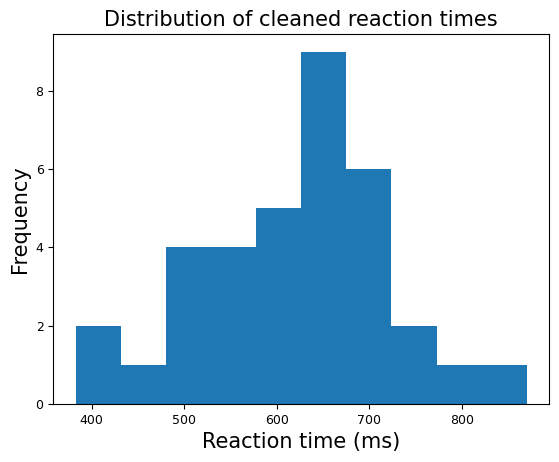

In [98]:
# EXAMPLE 0: histogram of reaction time

RT = data_clean['reaction_time_ms']

# mandatory import for plotting
import matplotlib.pyplot as plt

# Plot:
plt.subplots()
# histogram
plt.hist(RT)
# Axes labels and title
plt.xlabel("Reaction time (ms)")   # label on the x-axis
plt.ylabel("Frequency")            # label on the y-axis
plt.title("Distribution of cleaned reaction times") # title of the plot

# Show the plot
plt.show()

### Note! you can modify the size of the figure with the command
# plt.subplots(figsize=(length,height))
# EXAMPLE plt.subplots(figsize=(length,height))

***Minimal syntax***:

- `plt.hist( array_to_plot )`

 <br>

***Optional parameters***:

- **bins** : integer number [default: 10] <br> `plt.hist( array_to_plot , bins= number_of_bins )`  <br>

- **color** : [default: 'C0'] <br> `plt.hist( array_to_plot , color='blue' )`  <br>

- **range** : range of values [default: (min(array_to_plot),max(array_to_plot)] <br> `plt.hist( array_to_plot , range=(min_value, max_value) )`  <br>

- **histtype** : {'bar', 'barstacked', 'step', 'stepfilled'}, [default: 'bar'] <br> `plt.hist( array_to_plot , histtype='step' )`  <br>

- ...... and many others!

 <br>

If you google *matplotlib histogram*, you will easily find [this documentation page](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html), which explain the syntax of the 'hist' plotting function.

 <br>


### **<font color="red">C</font><font color="orange">o</font><font color="pink">l</font><font color="lightgreen">o</font><font color="teal">r</font><font color="blue">s</font>**

At [this link](https://matplotlib.org/stable/gallery/color/named_colors.html) you can find the basic list of colors for matplotlib.

----

### **Color**

#### **Syntax**

Color instruction is always to be given with a `string`.

##### **Color format**

The color string can be written as
- a color name (be sure that the color name exists in matplotlib)
- an hex RGB string
- ....
you can find [here](https://matplotlib.org/stable/users/explain/colors/colors.html#) the entire list of color formats


Examples:
- `color='k'`
- `color='black'`
- `color='tab:blue'`
- `color='#AA1BC0'`

----

### **Color Transparency**

You can control the level of transparency of EACH plot.

#### **Syntax**

`alpha = <float number between 0 and 1>`

The alpha keyword is the only tool needed to add transparency to a color. Its value goes from 0 to 1 (decimal number), where

- `alpha=0` means "completely transparent"
- `alpha=1` means "NOT transparent at all"


Text(0.5, 1.0, 'Distribution of cleaned reaction times')

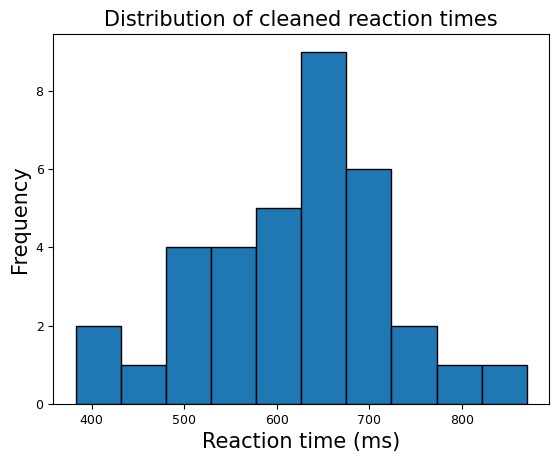

In [99]:
# EXAMPLE 1: Color and edgecolor

import matplotlib.pyplot as plt

RT = data_clean['reaction_time_ms']

# Plot:
plt.subplots()

# histogram of RT – 21 bins
plt.hist(RT, color='tab:blue', edgecolor='k')

# NOTE:
#plt.hist(RT, color='tab:blue', edgecolor='k', alpha=0.5)

plt.xlabel("Reaction time (ms)")   # label on the x-axis
plt.ylabel("Frequency")            # label on the y-axis
plt.title("Distribution of cleaned reaction times") # title of the plot


Text(0.5, 1.0, 'Distribution of cleaned reaction times')

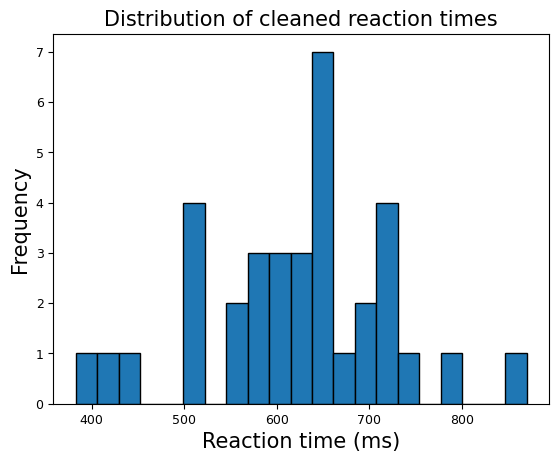

In [100]:
# EXAMPLE 2: Number of bins

import matplotlib.pyplot as plt

RT = data_clean['reaction_time_ms']

# Plot:
plt.subplots()

# histogram of RT – 21 bins
plt.hist(RT, bins=21, color='tab:blue', edgecolor='k')

plt.xlabel("Reaction time (ms)")   # label on the x-axis
plt.ylabel("Frequency")            # label on the y-axis
plt.title("Distribution of cleaned reaction times") # title of the plot


Text(0.5, 1.0, 'Distribution of cleaned reaction times')

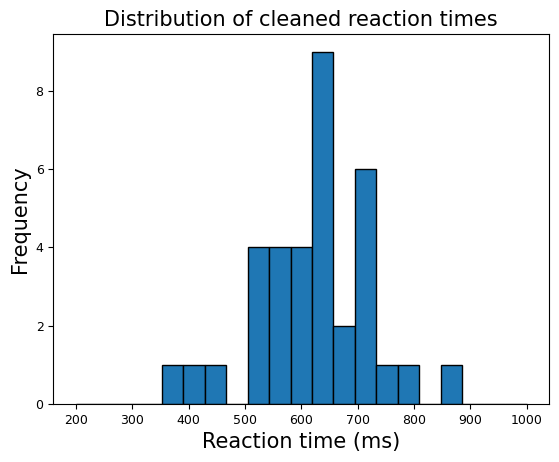

In [101]:
# EXAMPLE 3: Range

import matplotlib.pyplot as plt

RT = data_clean['reaction_time_ms']

# Plot:
plt.subplots()

# histogram of RT – 21 bins
plt.hist(RT, bins=21, range=(200,1000), color='tab:blue', edgecolor='k')

plt.xlabel("Reaction time (ms)")   # label on the x-axis
plt.ylabel("Frequency")            # label on the y-axis
plt.title("Distribution of cleaned reaction times") # title of the plot


Text(0.5, 1.0, 'Distribution of cleaned reaction times')

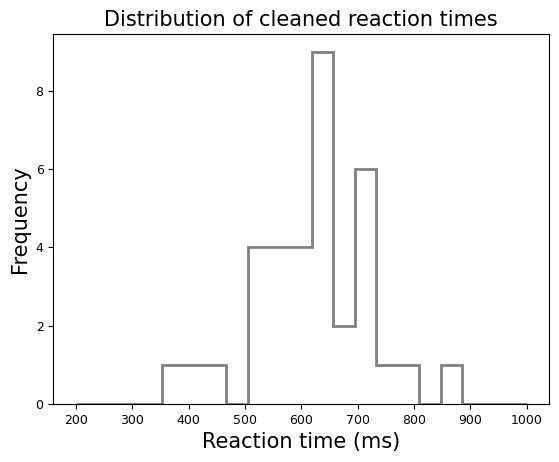

In [102]:
# EXAMPLE 4:  histtype  and  linewidth
plt.subplots()
plt.hist(RT, bins=21,  range=(200,1000), edgecolor='grey', linewidth=2, histtype='step')              # histogram of RT – 21 bins
plt.xlabel("Reaction time (ms)")   # label on the x-axis
plt.ylabel("Frequency")            # label on the y-axis
plt.title("Distribution of cleaned reaction times") # title of the plot


## **2. Using multiple plotting**

It is possible to add multiple plots to the same figure.

When we plot more than one dataset in the same graph, it is useful to add a **legend**.

A legend explains which line, graph, color, or marker corresponds to its own specific description.

### **Legend**

To create a legend, we add a `label` inside each plotting command:

```python
plt.hist(RT_neutral, label="Neutral")
plt.hist(RT_time_pressure, label="Time pressure")
plt.hist(RT_social_evaluation, label="Social evaluation")


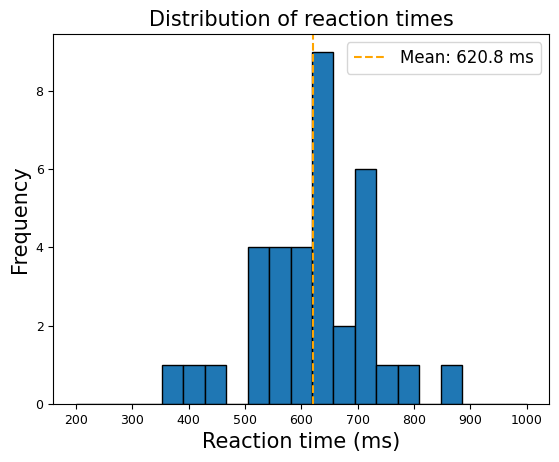

In [103]:
# EXAMPLE
# Plotting an histogram + mean

plt.subplots()

# histogram
plt.hist(RT, bins=21, range=(200,1000), color='tab:blue', edgecolor='k')

# vertical line (command: axvline)
plt.axvline(RT.mean(), color='orange', linestyle='--', label=f"Mean: {RT.mean():.1f} ms")

plt.xlabel("Reaction time (ms)")
plt.ylabel("Frequency")
plt.title("Distribution of reaction times")

plt.legend()


✏️ **It's your turn!**

Let's practice plotting histograms!<br>
Use the code cell below following the instructions within the comments. Try to write the code yourself to achieve the described results

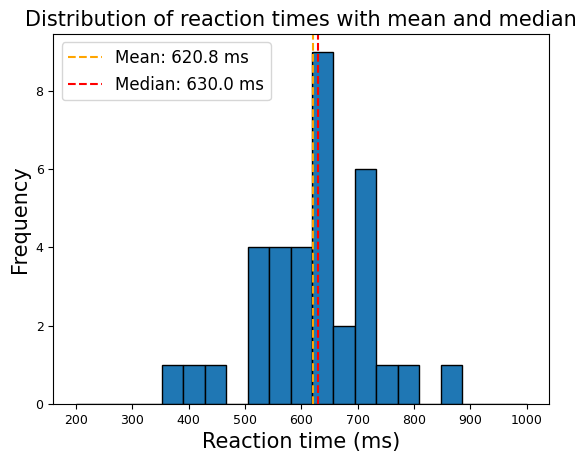

In [105]:
# EXERCISE 1:
# make a unique plot with
#  - the histogram of reaction-times
#  - the mean of reaction-times
#  - the median of reaction-times
# with appropriate colours and with leged.
# Legend should include the actual value of the mean and the median values
plt.hist(RT, bins=21, range=(200,1000), color='tab:blue', edgecolor='k')
plt.axvline(RT.mean(), color='orange', linestyle='--', label=f"Mean: {RT.mean():.1f} ms")
plt.axvline(RT.median(), color='red', linestyle='--', label=f"Median: {RT.median():.1f} ms")

plt.xlabel("Reaction time (ms)")
plt.ylabel("Frequency")
plt.title("Distribution of reaction times with mean and median")

plt.legend()

/tmp/ipykernel_637/890824098.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
/tmp/ipykernel_637/890824098.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


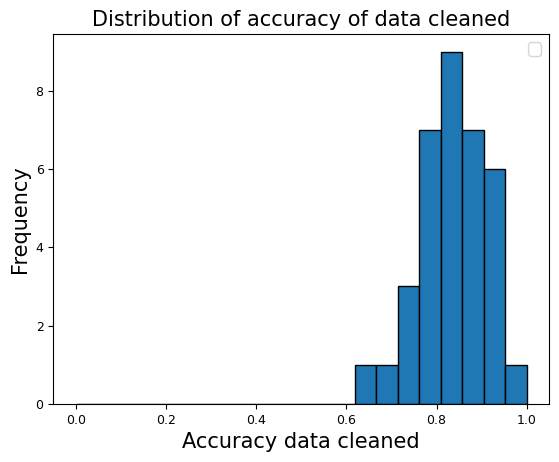

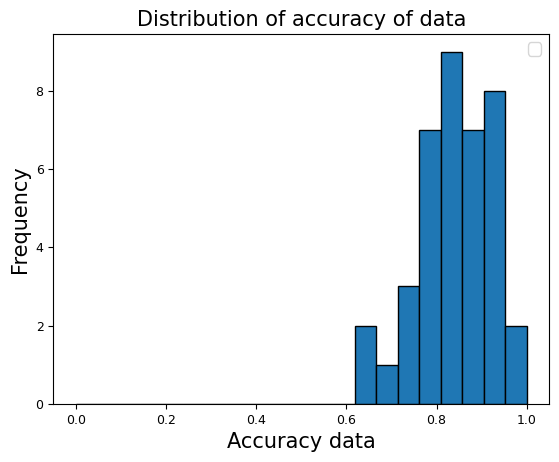

In [110]:
# EXERCISE 2:
# make a unique plot with
#  - the histogram of the accuracy BEFORE DATA CLEANING
#  - the histogram of the accuracy AFTER DATA CLEANING
# with appropriate colours and with leged.

plt.hist(data_clean["accuracy"], bins=21, range=(0,1), color='tab:blue', edgecolor='k')

plt.xlabel("Accuracy data cleaned")
plt.ylabel("Frequency")
plt.title("Distribution of accuracy of data cleaned")

plt.legend()
plt.subplots()
plt.hist(data["accuracy"], bins=21, range=(0,1), color='tab:blue', edgecolor='k')

plt.xlabel("Accuracy data")
plt.ylabel("Frequency")
plt.title("Distribution of accuracy of data")

plt.legend()

# Suggestion! Use the same range and the same number of bins to plot both the 2 histograms

### 🎁 **BONUS:**  Plot histogram + other statistical measures with multiple plotting

In [111]:
# Plot histogram for reaction time with mean, median, Q1 and Q3

# compute metrics
RT = data_clean['reaction_time_ms']

Q1 = RT.quantile(0.25)
Q3 = RT.quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print('----- IQR -----')
print(f"Q1 (25%): {Q1:,.0f} ms")
print(f"Q3 (75%): {Q3:,.0f} ms")
print(f"IQR: {IQR:,.0f} ms")
print(f"Lower limit: {lower_limit:,.0f} ms")
print(f"Upper limit: {upper_limit:,.0f} ms")



----- IQR -----
Q1 (25%): 570 ms
Q3 (75%): 690 ms
IQR: 120 ms
Lower limit: 391 ms
Upper limit: 869 ms


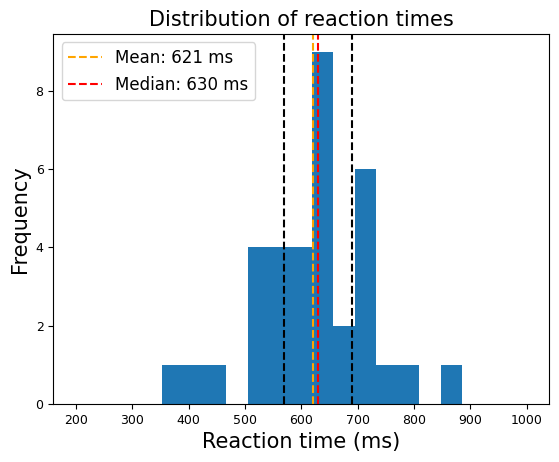

In [112]:
# Plotting an histogram + IQR
RT_clean = data_clean['reaction_time_ms']

plt.subplots()
plt.hist(RT, bins=21, range=(200,1000), color='tab:blue')
plt.axvline(RT.mean(), color='orange', linestyle='--', label=f"Mean: {RT.mean():.0f} ms")
plt.axvline(RT.median(), color='red', linestyle='--', label=f"Median: {RT.median():.0f} ms")
plt.axvline(Q1, color='k', linestyle='--')
plt.axvline(Q3, color='k', linestyle='--')

plt.xlabel("Reaction time (ms)")
plt.ylabel("Frequency")
plt.title("Distribution of reaction times")

plt.legend()


### 🎁 **BONUS:**  Density plot (KDE)

A **density plot** shows a smoothed estimate of the distribution.

It is often overlaid on a histogram to make the overall shape easier to see.

The **Kernel Density Estimate (KDE)** does not count observations in fixed bins. Instead, it estimates a smooth curve representing where values are more or less concentrated.

### seaborn

To show a density plot, we have to use `seaborn` library.


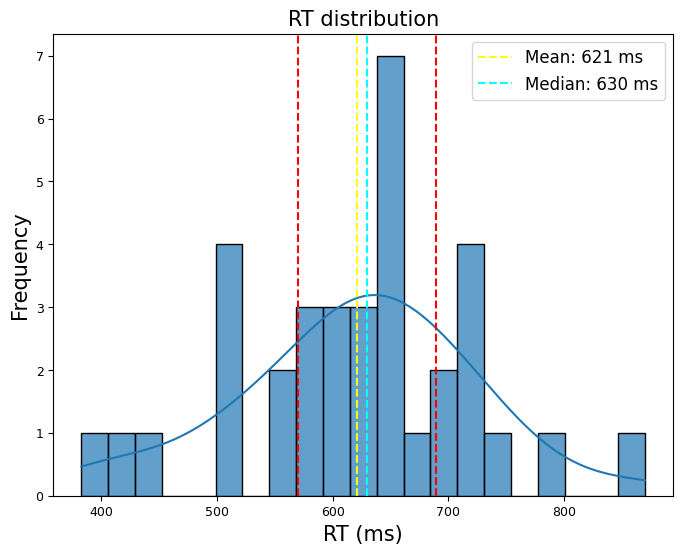

In [113]:
# Histogram with KDE

# To use KDE we shoud use seaborn:
import seaborn as sns

# PLOT
plt.subplots(figsize=(8, 6))

# histogram with kde
sns.histplot(RT_clean, bins=21, kde=True, color='tab:blue', edgecolor='black', alpha=0.7)

# plot vertical lines for Q1, Q3, mean and median
plt.axvline(Q1, color='red', linestyle='--')
plt.axvline(Q3, color='red', linestyle='--')
plt.axvline(RT_clean.mean(), color='yellow', linestyle='--', label=f"Mean: {RT_clean.mean():.0f} ms")
plt.axvline(RT_clean.median(), color='cyan', linestyle='--', label=f"Median: {RT_clean.median():.0f} ms")

plt.title('RT distribution')
plt.xlabel('RT (ms)')
plt.ylabel('Frequency')
plt.legend()



## **3. Boxplot**

A **boxplot** summarizes the distribution of a numerical variable using the median, quartiles, and possible outliers.

- The **central line** represents the median, or second quartile ($Q_2$).
- The **box edges** represent the first quartile ($Q_1$) and third quartile ($Q_3$).
- The **box** contains the central 50% of the data, also called the interquartile range (IQR).
- The **whiskers** extend to the most extreme values that are not considered outliers, usually according to the 1.5 $\times$ IQR rule.
- Individual points beyond the whiskers are shown as possible **outliers**.

Boxplots are especially useful for comparing the distribution of a variable across groups or experimental conditions.

### **seaborn library**

To create more advanced and readable plots, we can use the `seaborn` library.

`matplotlib` is very useful and flexible, but some plots require more manual work.

For example, if we want to compare a numerical variable across groups, `seaborn` is easier because it works directly with pandas DataFrames.

For this reason, `seaborn` is especially useful for grouped plots, such as:

- boxplots;
- stripplots;
- violin plots;
- density plots;
- scatterplots with groups.

In this course, we use `seaborn` when we want clearer and simpler syntax for statistical visualizations.


Text(0, 0.5, 'Reaction-time (ms)')

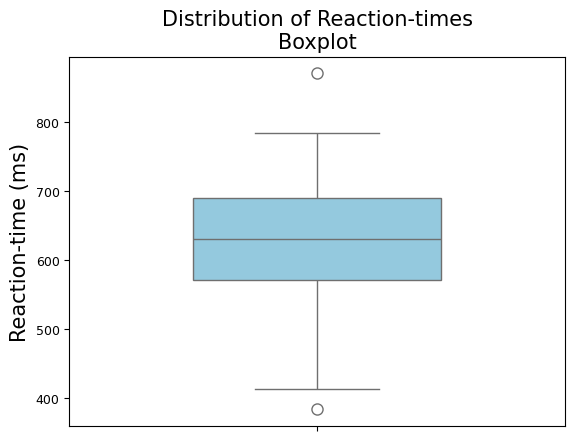

In [114]:
# Boxplot of one variable

RT = data_clean['reaction_time_ms']

# import seaborn to plot boxplots of a dataframe
import seaborn as sns

# PLOT
plt.subplots()

# Boxplot: shows the distribution of reaction times
sns.boxplot(RT,  color='skyblue', width=0.5, fliersize=8)

# title and y-axis label
plt.title('Distribution of Reaction-times\nBoxplot')
plt.ylabel('Reaction-time (ms)')


Q1 = 570.00 ms
Median = 630.00 ms
Q3 = 689.50 ms


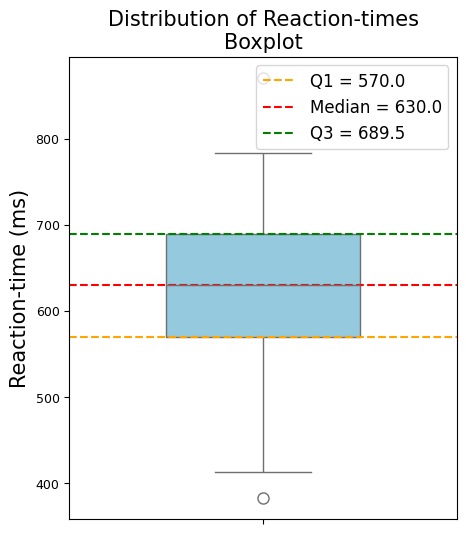

In [115]:
# Boxplot of one variable

RT = data_clean["reaction_time_ms"]

# Import seaborn to plot boxplots of a dataframe
import seaborn as sns

# Compute quartiles
Q1 = RT.quantile(0.25)
Q2 = RT.quantile(0.50)   # median
Q3 = RT.quantile(0.75)

print(f"Q1 = {Q1:.2f} ms")
print(f"Median = {Q2:.2f} ms")
print(f"Q3 = {Q3:.2f} ms")

# Plot
plt.figure(figsize=(5, 6))

# Boxplot: shows the distribution of reaction times
sns.boxplot(y=RT, color="skyblue", width=0.5, fliersize=8)

# Add quartile lines
plt.axhline(Q1, color="orange", linestyle="--", label=f"Q1 = {Q1:.1f}")
plt.axhline(Q2, color="red", linestyle="--", label=f"Median = {Q2:.1f}")
plt.axhline(Q3, color="green", linestyle="--", label=f"Q3 = {Q3:.1f}")

# Title and y-axis label
plt.title("Distribution of Reaction-times\nBoxplot")
plt.ylabel("Reaction-time (ms)")

plt.legend()
plt.show()

#### Plotting two groups or conditions

With boxplots, we can compare a numerical variable across different groups or conditions.

For example, we may ask:

> Do the control and clinical groups have different perceived stress scores?

In this case, one variable is categorical, such as `group`, and the other is quantitative, such as `perceived_stress`.


In [116]:
print(data_clean.columns.to_list())

['participant_id', 'age', 'gender', 'group', 'condition', 'anxiety_score', 'depression_score', 'perceived_stress', 'sleep_hours', 'accuracy', 'reaction_time_ms']



Syntax:

```python
sns.boxplot(data=data_clean, x="group", y="perceived_stress")
```

Meaning:

> Use the dataset `data_clean`, put the variable `group` on the x-axis, and plot the values of `perceived_stress` on the y-axis.



Text(0.5, 1.0, 'Perceived stress by group')

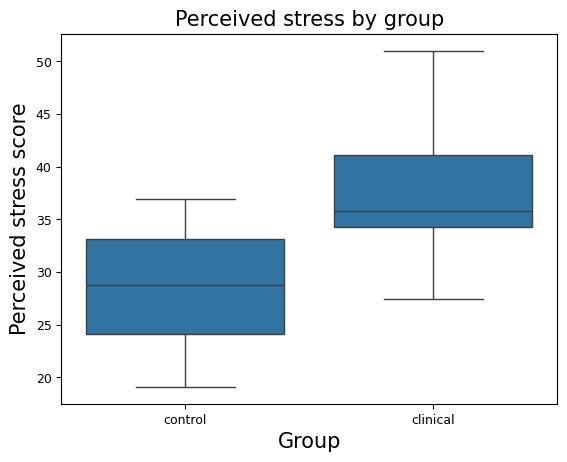

In [117]:
# EXAMPLE: Boxplot to compare two variables

# PLOT
plt.subplots()

# Boxplot: shows the distribution of perceived stress in each group
#          x = categorical variable
#          y = numerical variable
sns.boxplot(data=data_clean, x="group", y="perceived_stress", color='tab:blue')

plt.xlabel("Group")
plt.ylabel("Perceived stress score")
plt.title("Perceived stress by group")


Text(0.5, 1.0, 'Perceived stress by group')

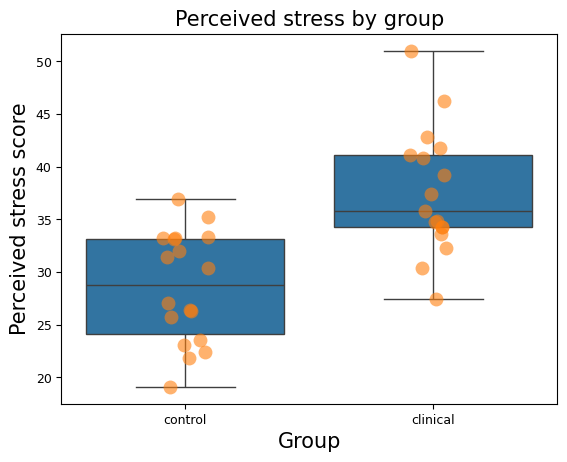

In [118]:
# EXAMPLE (OPTIONAL): Boxplot + stripplot

plt.subplots()

# Boxplot: shows the distribution of perceived stress in each group
sns.boxplot(data=data_clean, x="group", y="perceived_stress", color='tab:blue')
# Stripplot: shows each individual participant as a dot
sns.stripplot(data=data_clean, x="group", y="perceived_stress", size=10, alpha=0.6, color='tab:orange')

plt.xlabel("Group")
plt.ylabel("Perceived stress score")
plt.title("Perceived stress by group")


✏️ **It's your turn!**

Let's practice plotting boxplots!<br>
Use the code cell below following the instructions within the comments. Try to write the code yourself to achieve the described results

Text(0.5, 1.0, 'Perceived stress by condition')

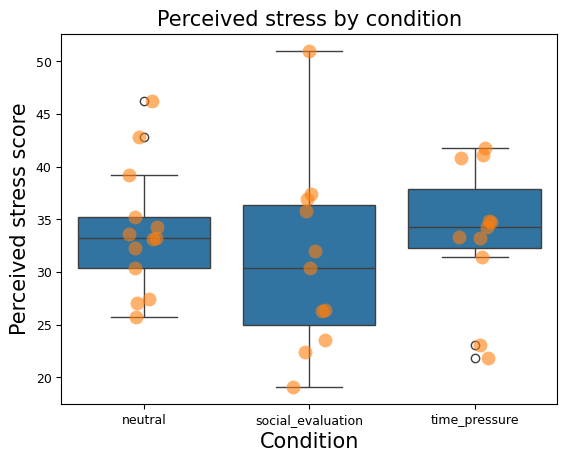

In [119]:
# EXERCISE 1:
# Create a boxplot showing the distribution of perceived stress
# for each experimental condition.
#
# Use:
# - the dataset: data_clean
# - the grouping variable on the x-axis: "condition"
# - the numerical variable on the y-axis: "perceived_stress"
#
# Add:
# - an x-axis label
# - a y-axis label
# - a clear title
#
# Optional:
# Add a stripplot to show the individual data points.
sns.boxplot(data=data_clean, x="condition", y="perceived_stress", color='tab:blue')
sns.stripplot(data=data_clean, x="condition", y="perceived_stress", size=10, alpha=0.6, color='tab:orange')

plt.xlabel("Condition")
plt.ylabel("Perceived stress score")
plt.title("Perceived stress by condition")

Text(0.5, 1.0, 'Perceived stress by group')

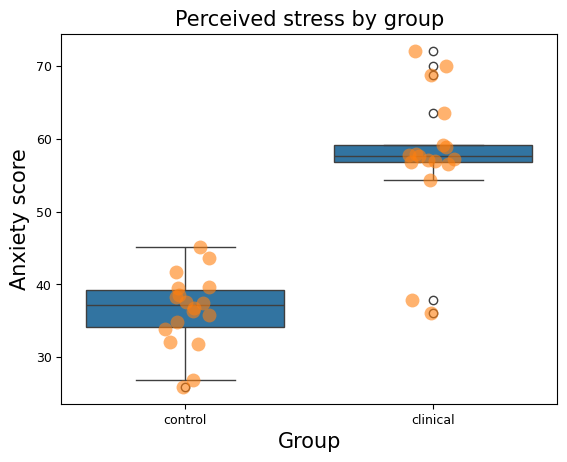

In [120]:
# EXERCISE 2:
# Create a boxplot showing the distribution of anxiety scores
# for each group.
#
# Use:
# - the dataset: data_clean
# - the grouping variable on the x-axis: "group"
# - the numerical variable on the y-axis: "anxiety_score"
#
# Add:
# - an x-axis label
# - a y-axis label
# - a clear title
#
# Optional:
# Add a stripplot to show the individual data points.
sns.boxplot(data=data_clean, x="group", y="anxiety_score", color='tab:blue')
sns.stripplot(data=data_clean, x="group", y="anxiety_score", size=10, alpha=0.6, color='tab:orange')

plt.xlabel("Group")
plt.ylabel("Anxiety score")
plt.title("Perceived stress by group")

### 🎁 **BONUS:**  Plotting boxplots with matplotlib

Text(0, 0.5, 'Stress scores')

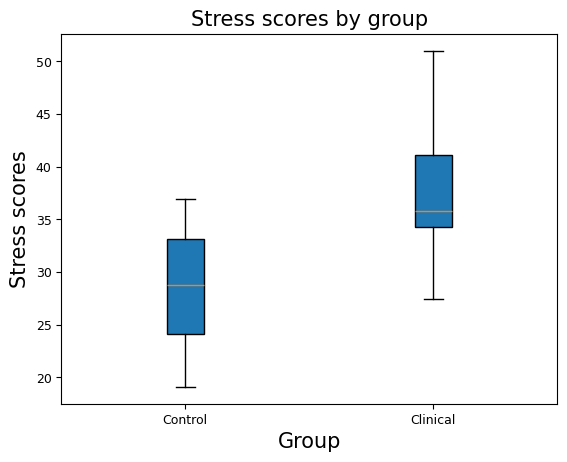

In [121]:
# Select stress scores for each group
control_scores  = data_clean[data_clean["group"] == "control"]["perceived_stress"]   # select only the rows where the group is "control"
clinical_scores = data_clean[data_clean["group"] == "clinical"]["perceived_stress"] # select only the rows where the group is "experimental"

plt.subplots()

# Create a boxplot
box = plt.boxplot([control_scores, clinical_scores], tick_labels=["Control", "Clinical"], patch_artist=True)

# Change box colors
box["boxes"][0].set_facecolor("tab:blue")
box["boxes"][1].set_facecolor("tab:blue")

# Add a title and axis labels
plt.title("Stress scores by group")
plt.xlabel("Group")
plt.ylabel("Stress scores")


With `matplotlib`, we first need to manually separate the data:

```python
control_scores = data_clean.loc[data_clean["group"] == "control", "perceived_stress"]
clinical_scores = data_clean.loc[data_clean["group"] == "clinical", "perceived_stress"]

plt.boxplot([control_scores, clinical_scores], tick_labels=["Control", "Clinical"])
plt.show()
```

With `seaborn`, we can directly tell Python:

- which dataset to use;
- which column defines the groups;
- which column contains the values to plot.

```python
sns.boxplot(data=data_clean, x="group", y="perceived_stress")
plt.show()
```

This syntax is easier to read:

```python
sns.boxplot(data=data_clean, x="group", y="perceived_stress")
```

means:

> Use the dataset `data_clean`, put the variable `group` on the x-axis, and plot the values of `perceived_stress` on the y-axis.


## **4. Scatterplots**

### **Studying the relationship between two variables**

So far, we started comparing one quantitative variable across groups or conditions using boxplots.

With **scatterplots**, the logic is different.<br>
We study two quantitative variables measured on the same participants.

The main question is:

> When one variable changes, does the other variable also tend to change?

For example:

- Do participants with higher **anxiety** also show higher **perceived stress**?
- Do participants with <u>higher</u> **depression** scores also have <u>slower</u> **reaction times**?


---



### **What is a Scatterplot**

A simple way to study the relationship between two quantitative variables is a **scatterplot**.

In a scatterplot:

- each dot represents one participant or one observation;
- the x-axis shows one variable;
- the y-axis shows another variable.

For example:

If the points tend to go upward from left to right, the relationship is **positive**.

If the points tend to go downward from left to right, the relationship is **negative**.

If the points are very scattered and show no clear direction, the relationship is **weak or absent**.

---

## **Positive relationship**

A positive relationship means that higher values of one variable tend to be associated with higher values of the other variable.

Example:

> Participants with higher anxiety tend to report higher perceived stress.

Graphically, the points tend to go upward:

```text
y
|        *
|      *
|    *
|  *
|*
|____________ x
```

---

## **Negative relationship**

A negative relationship means that higher values of one variable tend to be associated with lower values of the other variable.

Example:

> Participants with higher interoceptive accuracy may show lower alexithymia scores.

Graphically, the points tend to go downward:

```text
y
|*
|  *
|    *
|      *
|        *
|____________ x
```

---

## **No clear relationship**

Sometimes there is no clear pattern.

Example:

> Anxiety score and age may not show a clear relationship in the dataset.

Graphically, the points look scattered:

```text
y
|   *     *
| *    *
|     *    *
|  *      *
|____________ x
```




### **Correlation**

A scatterplot gives us a visual idea of the relationship.

To summarize this relationship with a number, we can compute a **correlation**.

The most common correlation is the **Pearson correlation coefficient**, usually called $r$.

The value of $r$ is always between `-1` and `+1`.

| Value of $r$ | Meaning |
|---|---|
| close to `+1` | strong positive relationship |
| close to `0` | weak or no linear relationship |
| close to `-1` | strong negative relationship |

For example:

```python
from scipy.stats import pearsonr

r_value, p_value = pearsonr(data_clean["anxiety_score"], data_clean["perceived_stress"])

print(f"Correlation: {r_value:.3f}")
print(f"P-value: {p_value:.3f}")
```

---

## **How to interpret correlation**

The correlation tells us two things:

### **1. Direction**

The sign tells us the direction of the relationship.

- If $r > 0$, the relationship is positive.
- If $r < 0$, the relationship is negative.
- If $r \approx 0$, there is no clear linear relationship.

### **2. Strength**

The size of $r$ tells us how strong the relationship is.

As a rough guide:

| Correlation | Interpretation |
|---|---|
| around `0.1` | weak |
| around `0.3` | moderate |
| around `0.5` or higher | strong |

These are only rough guidelines. The interpretation also depends on the research field, the sample size, and the data.

---

## **Important note**

Correlation does **not** mean causation.

If two variables are correlated, this means they are statistically associated.

It does not mean that one variable causes the other.

For example, if anxiety and perceived stress are positively correlated, we can write:

> Participants with higher anxiety tended to report higher perceived stress.

But we should not write:

> Anxiety caused perceived stress.

---

## **Summary**

To study the relationship between two quantitative variables:

1. Make a scatterplot.
2. Look at the direction of the points.
3. Compute the Pearson correlation.
4. Interpret the sign, strength, and p-value.
5. Remember that correlation does not imply causation.

### Example: **Research question**

Are anxiety and depression scores associated?

In this example:

- `anxiety_score` is the first quantitative variable;
- `depression_score` is the second quantitative variable.

We expect these variables to be positively correlated: participants with higher anxiety scores may also tend to have higher depression scores.

#### **Plot the relationship**

Before computing the correlation, we visualize the relationship using a scatterplot.

Each point represents one participant.

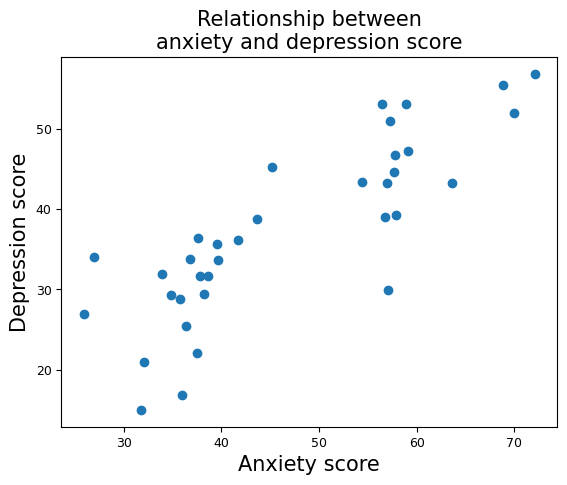

In [122]:
# Let's plot their relationship

plt.scatter(data_clean["anxiety_score"], data_clean["depression_score"])

plt.xlabel("Anxiety score")
plt.ylabel("Depression score")
plt.title("Relationship between\nanxiety and depression score")

plt.show()

We can also add a regression line to make the linear trend easier to see.

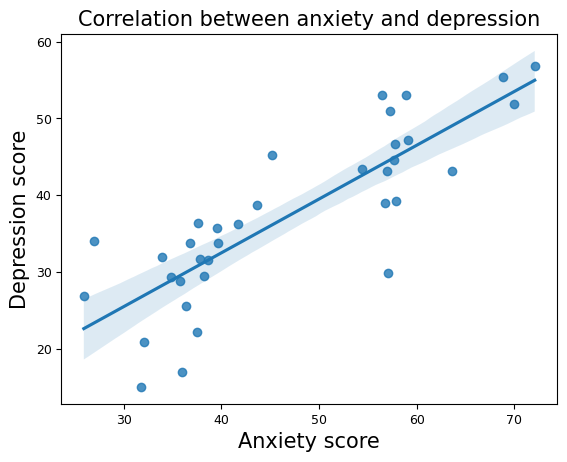

In [123]:
# we can plot also
sns.regplot(data=data_clean, x="anxiety_score", y="depression_score")

plt.xlabel("Anxiety score")
plt.ylabel("Depression score")
plt.title("Correlation between anxiety and depression")#+fr'$\rho={round(r_value,3)} - p={p_value:.3f}$')
plt.show()

#### **Compute Pearson correlation**

We now compute the Pearson correlation coefficient and its p-value.

The correlation coefficient tells us the strength and direction of the relationship.

The p-value tells us whether the observed correlation is unlikely under the null hypothesis of no linear association.

In [125]:
from scipy.stats import pearsonr

# Compute the pearson correlation between the Anxiety score and the Depression score
r_value, p_value = pearsonr(data_clean["anxiety_score"], data_clean["depression_score"])

print(f"r = {r_value:.3f}")
print(f"p = {p_value:.3f}")

r = 0.833
p = 0.000


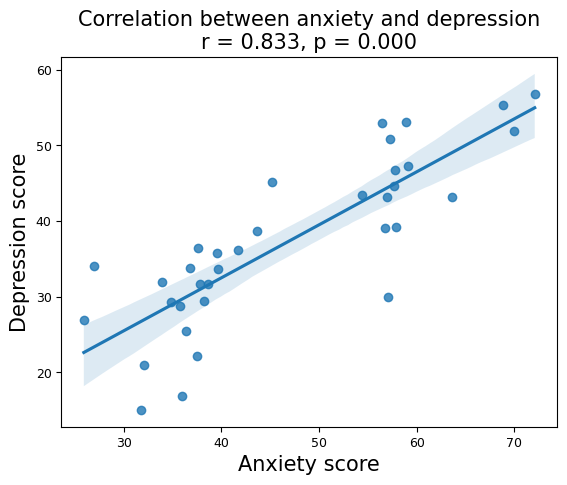

In [126]:
# PLOT + correlation in the title
plt.subplots()
sns.regplot(data=data_clean, x="anxiety_score", y="depression_score")

plt.xlabel("Anxiety score")
plt.ylabel("Depression score")
plt.title(f"Correlation between anxiety and depression\nr = {r_value:.3f}, p = {p_value:.3f}")
plt.show()


#### **Interpret the correlation**

A correlation tells us **whether two variables are  associated**.

In [127]:
if p_value < 0.05:
    print("Anxiety and depression scores are significantly correlated.")
else:
    print("Anxiety and depression scores are not significantly correlated.")

Anxiety and depression scores are significantly correlated.


✏️ **It's your turn!**

Let's practice correlation and its interpretation!<br>
Use the code cell below following the instructions within the comments. Try to write the code yourself to achieve the described results

In [128]:
# EXERCISE:
# Interpret the correlation results.
#
# The variables r_value and p_value have already been computed.
#
# Write an if/elif/else structure to print:
#
# 1) The direction of the relationship:
#    - positive if r_value is greater than 0
#    - negative if r_value is smaller than 0
#    - no linear relationship if r_value is equal to 0
#
# 2) The strength of the relationship:
#    - strong if the absolute value of r_value is greater than 0.7
#    - moderate if the absolute value of r_value is greater than 0.3
#    - weak otherwise
#
# 3) Whether the correlation is statistically significant:
#    - statistically significant if p_value is smaller than 0.05
#    - not statistically significant otherwise
if r_value>0:
  print("positive")

elif r_value<0:
  print("negative")

else:
  print("no linear relationship")

  if abs(r_value)>0.7:
    print("strong")
  elif abs(r_value)>0.3:
    print("moderate")
  else:
    print("weak")


  if p_value<0.05:
      print("statistically significant")
  else:
      print("not statistically significant")




positive


✏️ **It's your turn!**

Let's practice scatterplots and correlation!<br>
Use the code cell below following the instructions within the comments. Try to write the code yourself to achieve the described results

r = -0.758
p = 0.000


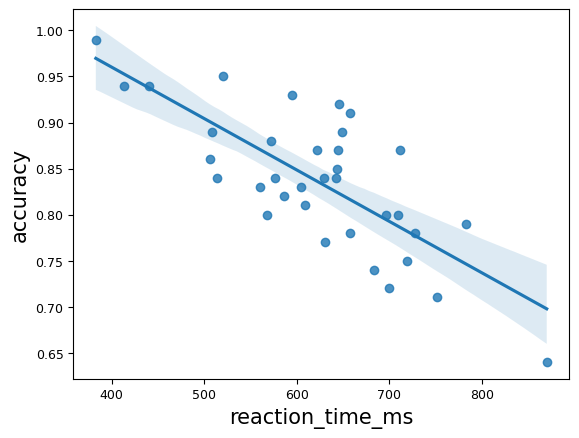

In [ ]:
# EXERCISE(S):
# Now choose two variables and investigate their relationship.

#For each pair of variables:
# 1. create a scatterplot;
# 2. add a regression line (optionsl);
# 3. compute the Pearson correlation coefficient;
# 4. interpret the direction, strength, and p-value.

# Try to find:
# - one pair of variables with a positive correlation;
# - one pair of variables with a weak or no correlation;
# - one pair of variables with a negative correlation.
#
# Suggested couples of variables:
# - reaction_time_ms vs accuracy
# - anxiety_score vs sleep_hours
# - age vs accuracy
# - age vs depression_score </i>

sns.regplot(data=data_clean, x='reaction_time_ms', y='accuracy')
r_value, p_value = pearsonr(data_clean["reaction_time_ms"], data_clean["accuracy"])
print(f"r = {r_value:.3f}")
print(f"p = {p_value:.3f}")


In [ ]:
# SECOND PAIR OF VARIABLES HERE

In [ ]:
# THIRD PAIR OF VARIABLES HERE

### **Correlation matrix**

When we have several numerical variables, it is useful to summarize all pairwise correlations in a **correlation matrix**.

A correlation matrix shows the Pearson correlation coefficient between each pair of variables.


This is useful for quickly exploring patterns in a psychological dataset and identifying which variables may be related.

In [ ]:
correlation_matrix = data_clean[numerical_variables].corr()

display(correlation_matrix)

,age,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
age,1.000000,-0.160091,-0.097765,-0.043874,0.253720,0.111379,-0.070118
anxiety_score,-0.160091,1.000000,0.832735,0.769553,0.022691,-0.067842,0.144808
depression_score,-0.097765,0.832735,1.000000,0.692693,0.109434,-0.110702,0.171687
perceived_stress,-0.043874,0.769553,0.692693,1.000000,-0.147152,0.085547,-0.116289
sleep_hours,0.253720,0.022691,0.109434,-0.147152,1.000000,0.174955,0.056553
accuracy,0.111379,-0.067842,-0.110702,0.085547,0.174955,1.000000,-0.758443
reaction_time_ms,-0.070118,0.144808,0.171687,-0.116289,0.056553,-0.758443,1.000000


#### 🎁 **BONUS: heatmap**

A **heatmap** is a visual representation of correlation matrix:

- each cell represents the correlation between two variables;
- the color indicates the strength and direction of the correlation;
- positive correlations and negative correlations are shown with different colors.

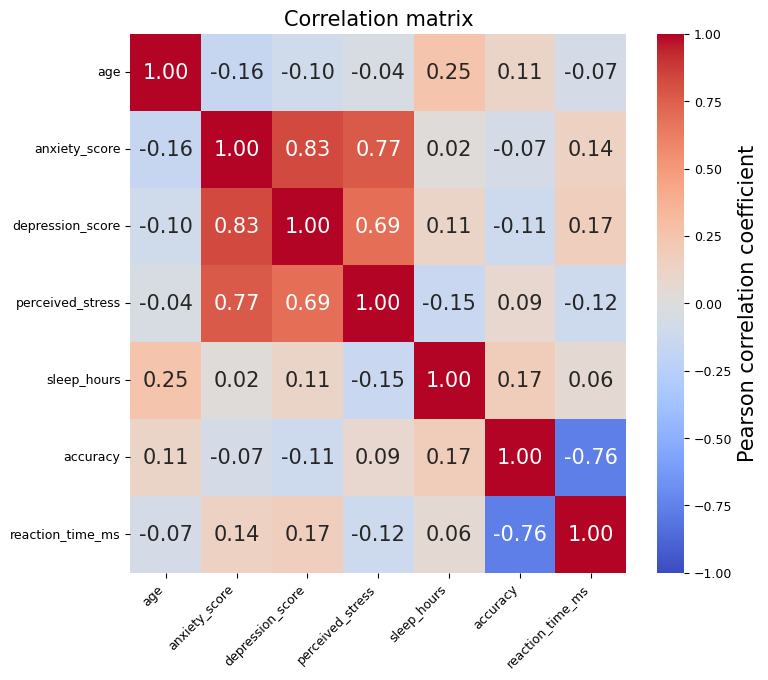

In [ ]:
plt.figure(figsize=(8, 7))

sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar_kws={"label": "Pearson correlation coefficient"})

plt.title("Correlation matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.show()

##### **🎁 How to read the heatmap**

Each cell of the heatmap contains a Pearson correlation coefficient.

- Values close to **+1** indicate a strong positive relationship.
- Values close to **-1** indicate a strong negative relationship.
- Values close to **0** indicate a weak or no linear relationship.

The diagonal is always equal to 1 because each variable is perfectly correlated with itself.

The heatmap helps us identify broad patterns before looking more closely at specific pairs of variables.

##### 🎁 **<font color="teal">Optional: p-values and multiple comparisons</font>**

The heatmap shows the correlation coefficient for each pair of variables.

However, if we want to know which correlations are statistically significant, we also need a p-value for each correlation.

Because we test many pairs of variables at the same time, we should correct for multiple comparisons. Otherwise, some correlations may appear significant just by chance.

Here, we use the Bonferroni correction, which is simple and conservative.

In [ ]:
from scipy.stats import pearsonr
from statsmodels.stats.multitest import multipletests

In [ ]:
X = data_clean[numerical_variables]
variables = X.columns
n_variables = len(variables)

p_values = []
pairs = []

for i in range(n_variables):
    for j in range(i + 1, n_variables):
        valid_data = X[[variables[i], variables[j]]].dropna()
        r_value, p_value = pearsonr(valid_data[variables[i]], valid_data[variables[j]])
        pairs.append((variables[i], variables[j], r_value, p_value))
        p_values.append(p_value)

##### 🎁 Bonferroni correction

When we test many correlations, the probability of finding a significant result just by chance increases.

The **Bonferroni correction** is a simple way to make the significance threshold more conservative.

Instead of using:

```text
p < 0.05
```

we divide `0.05` by the number of tests:

```text
corrected alpha = 0.05 / number of correlations
```

For example, if we test 5 correlations:

```text
corrected alpha = 0.05 / 5 = 0.01
```

So a correlation is considered statistically significant only if:

```text
p < 0.01
```

Use the Bonferroni correction when you run several correlations and want to reduce the risk of false positives.

In [ ]:
reject, corrected_p_values, _, _ = multipletests(p_values, alpha=0.05, method="bonferroni")

In [ ]:
correlation_results = pd.DataFrame(pairs, columns=["Variable 1", "Variable 2", "r", "p uncorrected"])
correlation_results["p corrected"] = corrected_p_values
correlation_results["Significant after correction"] = reject

correlation_results.sort_values("p corrected")

,Variable 1,Variable 2,r,p uncorrected,p corrected,Significant after correction
6,anxiety_score,depression_score,0.832735,5.506573e-10,1.156380e-08,True
7,anxiety_score,perceived_stress,0.769553,6.563435e-08,1.378321e-06,True
20,accuracy,reaction_time_ms,-0.758443,1.303663e-07,2.737693e-06,True
11,depression_score,perceived_stress,0.692693,4.006385e-06,8.413408e-05,True
3,age,sleep_hours,0.253720,1.413718e-01,1.000000e+00,False
2,age,perceived_stress,-0.043874,8.023877e-01,1.000000e+00,False
5,age,reaction_time_ms,-0.070118,6.889730e-01,1.000000e+00,False
0,age,anxiety_score,-0.160091,3.582748e-01,1.000000e+00,False
4,age,accuracy,0.111379,5.241367e-01,1.000000e+00,False
8,anxiety_score,sleep_hours,0.022691,8.970529e-01,1.000000e+00,False


RECAP: Bonferroni correction controls false positives by making the significance threshold more strict. It is simple but conservative.

##### 🎁 False discovery rate

FDR correction controls the expected proportion of false discoveries among significant results. It is less conservative and often used in exploratory analyses.

In [ ]:
reject, corrected_p_values, _, _ = multipletests(p_values, alpha=0.05, method="fdr_bh")

In [ ]:
significance_matrix = pd.DataFrame("", index=variables, columns=variables)

for _, row in correlation_results.iterrows():
    if row["Significant after correction"]:
        significance_matrix.loc[row["Variable 1"], row["Variable 2"]] = "*"
        significance_matrix.loc[row["Variable 2"], row["Variable 1"]] = "*"

significance_matrix

,age,anxiety_score,depression_score,perceived_stress,sleep_hours,accuracy,reaction_time_ms
age,,,,,,,
anxiety_score,,,*,*,,,
depression_score,,*,,*,,,
perceived_stress,,*,*,,,,
sleep_hours,,,,,,,
accuracy,,,,,,,*
reaction_time_ms,,,,,,*,


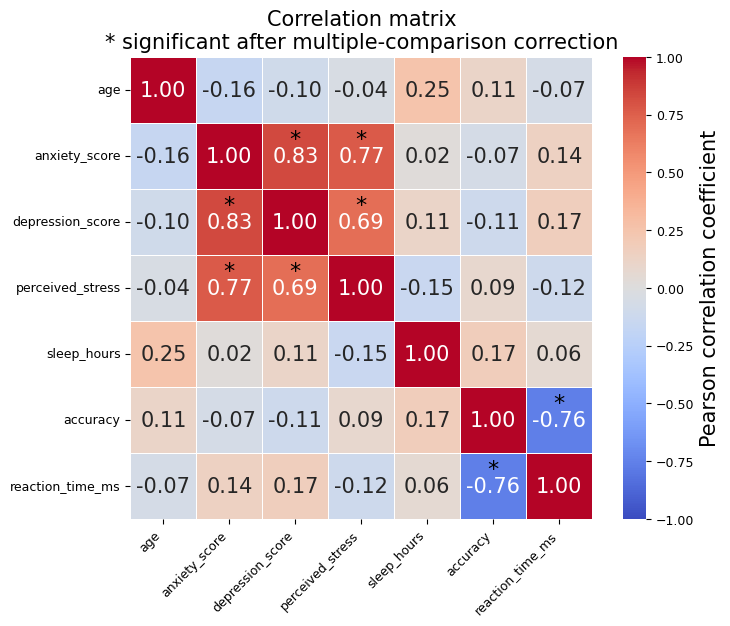

In [ ]:
plt.figure(figsize=(8, 6))

sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={"label": "Pearson correlation coefficient"})

for y, variable_y in enumerate(variables):
    for x, variable_x in enumerate(variables):
        if significance_matrix.loc[variable_y, variable_x] == "*":
            plt.text(x + 0.5, y + 0.25, "*", ha="center", va="center", color="black", fontsize=16)

plt.title("Correlation matrix\n* significant after multiple-comparison correction")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.show()

# **t-test**



## **1. <font color="orange">Independent-samples t-test</font>**

An independent-samples t-test is used when we want to compare the mean of a numerical variable between two different groups of participants.

In this example:

- the numerical variable is `anxiety_score`;
- the categorical variable is `group`;<br> the two groups are `control` and `clinical`.


### **Extract the two groups**

First, we split the data into the two groups we want to compare.

In [ ]:
control_anxiety = data_clean[data_clean["group"] == "control"]["anxiety_score"]
clinical_anxiety = data_clean[data_clean["group"] == "clinical"]["anxiety_score"]

In [ ]:
control_anxiety.mean(), clinical_anxiety.mean()

(np.float64(36.4388888888889), np.float64(57.576470588235296))

#### **Data visualization:** compare the 2 groups

With **small samples**, normality tests can be unstable. <br>

For this reason, it is also useful to inspect the data visually, for example using histograms or boxplots.


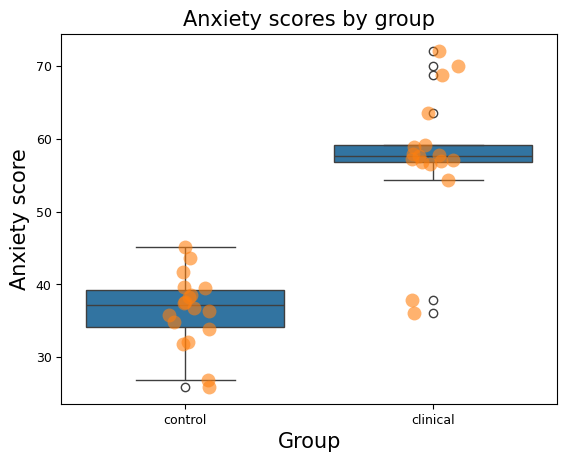

In [ ]:
# PLOT the QUANTITIES we want to compare
plt.subplots()
sns.boxplot(data=data_clean, x="group", y="anxiety_score", color='tab:blue')
sns.stripplot(data=data_clean, x="group", y="anxiety_score", size=10, alpha=0.6, color='tab:orange')

plt.xlabel("Group")
plt.ylabel("Anxiety score")
plt.title("Anxiety scores by group")
plt.show()

### **Two-sided t-test: Do the two groups differ?**

#### Independent-samples t-test: two-sided

Question: do `clinical` and `control` participants **differ** in anxiety scores?

In [ ]:
# Independent-samples t-test: two-sided
# Question: do clinical and control participants differ in anxiety scores?
from scipy.stats import ttest_ind

t_statistic, p_value = ttest_ind(clinical_anxiety, control_anxiety, equal_var=False, alternative="two-sided")

print("Two-sided test: clinical vs control")
print(f"t = {t_statistic:.3f}")
print(f"p = {p_value:.5f}")

Two-sided test: clinical vs control
t = 8.240
p = 0.00000


#### **Interpret the result**

We compare the p-value with the conventional significance threshold of 0.05.

- If `p < 0.05`, we conclude that the two groups differ significantly in their average anxiety score.

- If `p >= 0.05`, we do not have enough evidence to conclude that the two groups differ.

Remember: a significant result means that the group averages differ more than expected by chance. It does not mean that all participants in one group have higher scores than all participants in the other group.



### **One-sided t-test: is the clinical group higher?**

#### Independent-samples t-test: one-sided

Question: do clinical participants have higher anxiety scores than control participants?


In [ ]:
# Independent-samples t-test: one-sided
# Question: do clinical participants have higher anxiety scores than control participants?

t_statistic, p_value = ttest_ind(clinical_anxiety, control_anxiety, equal_var=False, alternative="greater")

print("One-sided test: clinical > control")
print(f"t = {t_statistic:.3f}")
print(f"p = {p_value:.5f}")

One-sided test: clinical > control
t = 8.240
p = 0.00000


**Note:** ORDERING is important here:

- `ttest_ind(clinical_anxiety, control_anxiety, alternative="greater")`

is aking the question "is `clinical_anxiety > control_anxiety``
"?

### **RECAP**

- Use `alternative="two-sided"` when the question is whether the two measurements are different.

- Use `alternative="greater"` when the question is specifically whether the first measurement is higher than the second one.


## **2. <font color="orange">Dependent-samples t-test</font>**

A dependent-samples t-test, also called a paired-samples t-test, is used when we want to compare the mean of a numerical variable between two related conditions.

The two measurements are not independent because they come from the same participants.

In this example, we imagine that 30 participants reported their anxiety score before and after a stressful task:

- the numerical variable is `anxiety_score`;
- the two related measurements are `anxiety_pre` and `anxiety_post`;
- each participant has both a pre-task and a post-task anxiety score.

The dependent-samples t-test evaluates whether the average within-participant difference between the two measurements is larger than what we would expect from random variation alone.

In [ ]:
from scipy.stats import ttest_rel

# Anxiety scores from the same participants before and after a stressful task
anxiety_pre  = [32, 35, 40, 28, 45, 38, 31, 36, 42, 34]
anxiety_post = [38, 39, 47, 35, 50, 41, 36, 40, 48, 39]

# Print means
print(f"Mean anxiety before the task: {sum(anxiety_pre) / len(anxiety_pre):.2f}")
print(f"Mean anxiety after the task: {sum(anxiety_post) / len(anxiety_post):.2f}")

Mean anxiety before the task: 36.10
Mean anxiety after the task: 41.30


### Visualize the data

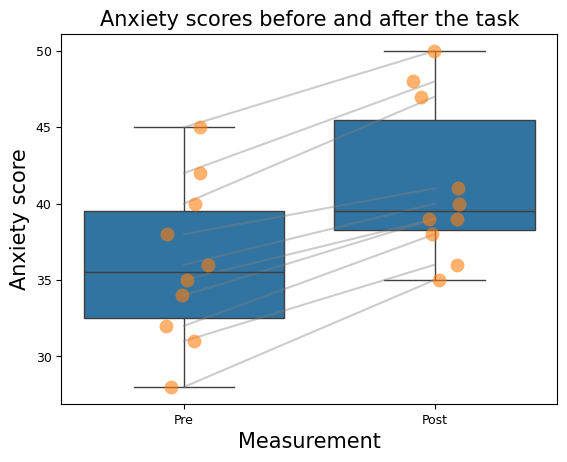

In [ ]:
# PLOT the QUANTITIES we want to compare
plt.subplots()

sns.boxplot(data=[anxiety_pre, anxiety_post], color="tab:blue")
sns.stripplot(data=[anxiety_pre, anxiety_post], size=10, alpha=0.6, color="tab:orange")

# OPTIONAL: Add lines connecting the same participants
for i in range(len(anxiety_pre)):
    plt.plot([0, 1], [anxiety_pre[i], anxiety_post[i]], color="gray", alpha=0.4)

plt.xticks([0, 1], ["Pre", "Post"])
plt.xlabel("Measurement")
plt.ylabel("Anxiety score")
plt.title("Anxiety scores before and after the task")
plt.show()

### Two-sided t-test

Question:

> Are **anxiety scores** <u>different</u> **before** and **after** the task?

In [ ]:
# Two-sided paired t-test
# Question: are anxiety scores different before and after the task?

t_statistic, p_value = ttest_rel(anxiety_post, anxiety_pre, alternative="two-sided")

print("Two-sided paired t-test: post vs pre")
print(f"t = {t_statistic:.3f}")
print(f"p = {p_value:.5f}")

Two-sided paired t-test: post vs pre
t = 12.490
p = 0.00000


#### **Interpret the result**

We compare the p-value with the conventional significance threshold of 0.05.

- If `p < 0.05`, we conclude that the two measurements differ significantly.

- If `p >= 0.05`, we do not have enough evidence to conclude that the two measurements differ.

In this example, a significant result means that the average within-participant difference between pre-task and post-task anxiety is larger than expected by random variation alone.

Remember: a significant result does not mean that anxiety increased for every participant. It means that, on average, the pre-task and post-task anxiety scores differ.

### Two-sided t-test

Question:

> Are **anxiety scores** <u>higher</u> after the task than before the task?

In [ ]:
# One-sided paired t-test
# Question: are anxiety scores higher after the task than before the task?

t_statistic, p_value = ttest_rel(anxiety_post, anxiety_pre, alternative="greater")

print("One-sided paired t-test: post > pre")
print(f"t = {t_statistic:.3f}")
print(f"p = {p_value:.5f}")

One-sided paired t-test: post > pre
t = 12.490
p = 0.00000


#### Interpretation

- If `p < 0.05`, we conclude that post-task anxiety is significantly higher than pre-task anxiety.

- If `p >= 0.05`, we do not have enough evidence to conclude that post-task anxiety is higher than pre-task anxiety.

### 🎁 BONUS: Check assumptions for t-test

Before running the t-test, we check whether the main assumptions are reasonable.

For an independent-samples t-test, we assume that:

1. observations are **independent**;
2. the variable is approximately **normally distributed** within each group;
3. the two groups have **similar variances**.

In real psychological data, these assumptions are often approximate rather than perfect. The goal is to check whether there are strong violations.

In [ ]:
if p_value < 0.05:
    print("The two groups differ significantly in anxiety scores.")
else:
    print("The two groups do not differ significantly in anxiety scores.")

The two groups differ significantly in anxiety scores.


# ANOVA

### **<font color="orange">Compare more than two conditions: one-way ANOVA</font>**

A one-way ANOVA is used when we want to compare the mean of a numerical variable across more than two groups or conditions.

Here, we ask:

**Do reaction times differ across experimental conditions?**

In this dataset:

- the numerical variable is `reaction_time_ms`;
- the grouping variable is `condition`;
- the three conditions are `neutral`, `social_evaluation`, and `time_pressure`.

The ANOVA tests whether at least one condition has a different mean reaction time from the others.

Importantly, ANOVA does not immediately tell us which specific conditions differ from each other. It only tells us whether there is evidence for a difference somewhere among the condition means.

In [ ]:
data_clean["condition"].value_counts()

,count
condition,
neutral,13
social_evaluation,11
time_pressure,11


### **Extract the reaction times for each condition**

Before running the ANOVA, we separate the reaction-time values according to the experimental condition.

This gives us three groups of values:

- reaction times in the `neutral` condition;
- reaction times in the `social_evaluation` condition;
- reaction times in the `time_pressure` condition.

The ANOVA will compare the mean reaction time across these three conditions.

In [ ]:
neutral_rt           = data_clean[data_clean["condition"] == "neutral"]["reaction_time_ms"]
social_evaluation_rt = data_clean[data_clean["condition"] == "social_evaluation"]["reaction_time_ms"]
time_pressure_rt     = data_clean[data_clean["condition"] == "time_pressure"]["reaction_time_ms"]

In [ ]:
print(f"Neutral: n = {len(neutral_rt)}")
print(f"Social evaluation: n = {len(social_evaluation_rt)}")
print(f"Time pressure: n = {len(time_pressure_rt)}")

Neutral: n = 13
Social evaluation: n = 11
Time pressure: n = 11


### Visualizing reaction-times by condition

Text(0.5, 1.0, 'Reaction times by experimental condition')

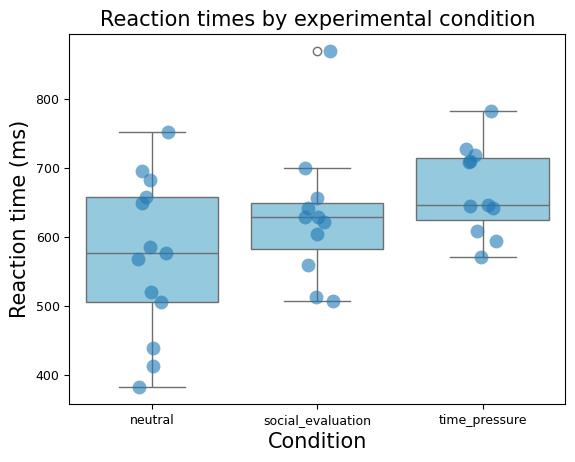

In [ ]:
sns.boxplot(data=data_clean, x="condition", y="reaction_time_ms", color='skyblue')
sns.stripplot(data=data_clean, x="condition", y="reaction_time_ms", size=10, alpha=0.6)

plt.xlabel("Condition")
plt.ylabel("Reaction time (ms)")
plt.title("Reaction times by experimental condition")


Text(0.5, 1.0, 'Mean reaction time by condition')

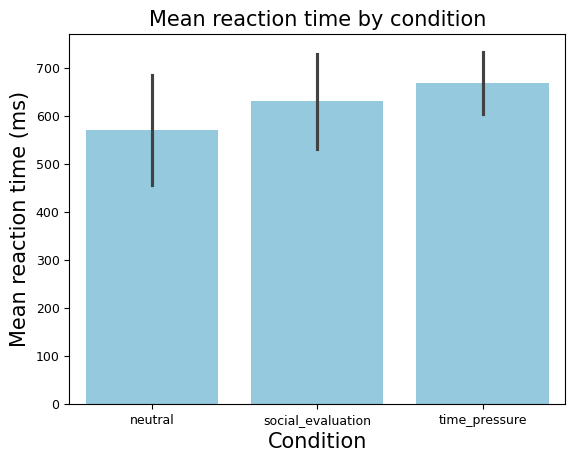

In [ ]:
# Barplot: mean and std by condition
sns.barplot(data=data_clean, x="condition", y="reaction_time_ms", errorbar="sd", color='skyblue')

plt.xlabel("Condition")
plt.ylabel("Mean reaction time (ms)")
plt.title("Mean reaction time by condition")


### 🎁 BONUS: **Check ANOVA assumptions**

Before running a one-way ANOVA, we check whether its main assumptions are reasonable.

The main assumptions are:

1. **Independence**: observations should be independent from each other.
2. **Approximate normality**: reaction times should be approximately normally distributed within each condition.
3. **Homogeneity of variance**: the variability of reaction times should be similar across conditions.

In real psychological data, these assumptions are **rarely** perfect.

The goal is to check whether there are strong violations that would make the ANOVA inappropriate.

### **Run the one-way ANOVA**

We now run a one-way ANOVA to test whether mean reaction time differs across the three experimental conditions.

The ANOVA returns two main values:

- `f_statistic`: the ratio between variability explained by the condition and unexplained variability within conditions;
- `p_value`: the probability of observing an effect this large, or larger, if there were actually no difference between the condition means.

If the p-value is below 0.05, we conclude that reaction times differ significantly across conditions.

In [ ]:
from scipy.stats import f_oneway
f_statistic, p_value = f_oneway(neutral_rt, social_evaluation_rt, time_pressure_rt)

print(f"F = {f_statistic:.3f}")
print(f"p = {p_value:.3f}")

F = 3.107
p = 0.058


### **Interpret the ANOVA result**

ANOVA tells us whether at least one condition differs from the others, but it does not tell us which specific conditions differ.

We compare the p-value with the conventional significance threshold of 0.05.

If `p < 0.05`, we conclude that at least one experimental condition has a different mean reaction time from the others.

If `p >= 0.05`, we do not have enough evidence to conclude that reaction times differ across conditions.

Importantly, a significant ANOVA does not tell us which specific conditions differ. It only tells us that there is evidence for a difference somewhere among the condition means.

In [ ]:
if p_value < 0.05:
    print("Reaction times differ significantly across conditions.")
else:
    print("Reaction times do not differ significantly across conditions.")

Reaction times do not differ significantly across conditions.
